In [2]:
from pathlib import Path
import sqlite3
import pandas as pd

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = PROJECT_DIR / "processed"
PLOTS_DIR = PROJECT_DIR / "Plots"

PROCESSED_DIR.mkdir(exist_ok=True)
PLOTS_DIR.mkdir(exist_ok=True)

DB_PATH = DATA_DIR / "PlasticEnz.db"

print("Project:", PROJECT_DIR)
print("Database:", DB_PATH)
print("Database exists:", DB_PATH.exists())

Project: d:\Machine-Learning\Paper-1\project
Database: d:\Machine-Learning\Paper-1\project\data\PlasticEnz.db
Database exists: True


In [3]:
import sqlite3
conn = sqlite3.connect(DB_PATH)

print("Connected to PlasticEnz database")

Connected to PlasticEnz database


In [4]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

tables

,name
0,sqlite_sequence
1,Plastic
2,Enzymes
3,Reaction
4,Microorganisms
5,Databases
6,Study
7,Main_copy
8,Sequences


In [5]:
main = pd.read_sql_query("SELECT * FROM Main_copy", conn)
enzymes = pd.read_sql_query("SELECT * FROM Enzymes", conn)
sequences = pd.read_sql_query("SELECT * FROM Sequences", conn)
plastics = pd.read_sql_query("SELECT * FROM Plastic", conn)

In [6]:
print("Main:", main.shape)
print("Enzymes:", enzymes.shape)
print("Sequences:", sequences.shape)
print("Plastics:", plastics.shape)

Main: (279, 13)
Enzymes: (62, 8)
Sequences: (272, 2)
Plastics: (13, 3)


In [7]:
print("MAIN")
print(main.columns.tolist())

print("\nENZYMES")
print(enzymes.columns.tolist())

print("\nSEQUENCES")
print(sequences.columns.tolist())

print("\nPLASTICS")
print(plastics.columns.tolist())

MAIN
['Genus', 'Species', 'Strain', 'Enzyme', 'Optimal_conditions', 'Main_Pk', 'Database_id', 'Sequences_id', 'Study_id', 'Enzymes_id', 'Microorganism_id', 'Reaction_id', 'Plastic_id']

ENZYMES
['Location', 'Gene', 'Type', 'Superfamily', 'Operon', 'Gene_Cluster', 'Catalytic domain', 'Enzymes_id']

SEQUENCES
['SEQUENCE', 'Seq_Pk']

PLASTICS
['Plastic_id', 'PLASTIC', 'TYPE']


In [8]:
feature_cols = [
    "Type",
    "Superfamily",
    "Catalytic domain",
    "Location"
]

for col in feature_cols:
    print(f"\n===== {col} =====")
    print(enzymes[col].value_counts(dropna=False))


===== Type =====
Type
Acting on ester bonds                                                           47
Acting on paired donors, with incorporation or reduction of molecular oxygen     7
Acting on peptide bonds                                                          4
Acting on diphenols and related substances as donors;                            1
Acting on the aldehyde or oxo group of donors                                    1
Acting on the CH-OH group of donors                                              1
Forming carbon-sulfur bonds                                                      1
Name: count, dtype: int64

===== Superfamily =====
Superfamily
Hydrolases         51
Oxidoreductases    10
Ligases             1
Name: count, dtype: int64

===== Catalytic domain =====
Catalytic domain
          29
NaN       27
Type 1     2
Type 2     1
Type 3     1
Type 4     1
Type 5     1
Name: count, dtype: int64

===== Location =====
Location
Extracellular          52
Cell inner membrane 

In [9]:
feature_summary = pd.DataFrame({
    "non_missing": enzymes[feature_cols].notna().sum(),
    "missing": enzymes[feature_cols].isna().sum(),
    "unique_values": enzymes[feature_cols].nunique(dropna=True)
})

feature_summary

,non_missing,missing,unique_values
Type,62,0,7
Superfamily,62,0,3
Catalytic domain,35,27,6
Location,62,0,5


In [10]:
enzymes[feature_cols].drop_duplicates().sort_values(feature_cols)

,Type,Superfamily,Catalytic domain,Location
20,Acting on diphenols and related substances as ...,Oxidoreductases,,Extracellular
5,Acting on ester bonds,Hydrolases,,Cell outer membrane
3,Acting on ester bonds,Hydrolases,,Extracellular
0,Acting on ester bonds,Hydrolases,Type 1,Extracellular
2,Acting on ester bonds,Hydrolases,Type 2,Extracellular
43,Acting on ester bonds,Hydrolases,Type 3,Extracellular
44,Acting on ester bonds,Hydrolases,Type 4,Extracellular
45,Acting on ester bonds,Hydrolases,Type 5,Extracellular
32,Acting on ester bonds,Hydrolases,NaN,Extracellular
21,"Acting on paired donors, with incorporation or...",Oxidoreductases,,Cell inner membrane


In [11]:
enzymes["Catalytic domain"].value_counts(dropna=False)

Catalytic domain
          29
NaN       27
Type 1     2
Type 2     1
Type 3     1
Type 4     1
Type 5     1
Name: count, dtype: int64

In [12]:
print("MAIN")
display(main.head())

print("ENZYMES")
display(enzymes.head())

print("SEQUENCES")
display(sequences.head())

print("PLASTICS")
display(plastics.head())

MAIN


,Genus,Species,Strain,Enzyme,Optimal_conditions,Main_Pk,Database_id,Sequences_id,Study_id,Enzymes_id,Microorganism_id,Reaction_id,Plastic_id
0,Streptomyces,hygroscopicus,ascomyceticus,PHB depolymerase,he enzyme was found to be a monomer with a mol...,1,1.0,1.0,1.0,1.0,1.0,1.0,3.0
1,Bacillus,megaterium,N-18-25-9,PHB depolymerase,The maximum activity was observed at pH 9.0 at...,2,2.0,2.0,2.0,2.0,2.0,1.0,3.0
2,Pseudomonas,lemoignei,,PHB depolymerase,NaN,3,3.0,3.0,3.0,2.0,3.0,1.0,3.0
3,Alcaligenes,faecalis,,PHB depolymerase,NaN,4,4.0,4.0,4.0,2.0,4.0,1.0,3.0
4,Ralstonia,pickettii,T1,PHB depolymerase,NaN,5,5.0,5.0,5.0,2.0,5.0,1.0,3.0


ENZYMES


,Location,Gene,Type,Superfamily,Operon,Gene_Cluster,Catalytic domain,Enzymes_id
0,Extracellular,fkbU (PhaZ),Acting on ester bonds,Hydrolases,,FK520,Type 1,1
1,Extracellular,PhaZ,Acting on ester bonds,Hydrolases,pha operon,,Type 1,2
2,Extracellular,PhaZ,Acting on ester bonds,Hydrolases,pha operon,,Type 2,3
3,Extracellular,AMED_7492,Acting on ester bonds,Hydrolases,,,,4
4,Extracellular,ISF6_4831,Acting on ester bonds,Hydrolases,,,,5


SEQUENCES


,SEQUENCE,Seq_Pk
0,MQPPPFRGILTPLFPLSSSPPVGSLSRPGRRGVLTRLVAVVALVLG...,1
1,MKRLFIAGMIFILFLSLGAVSSSAAGSFTSKTYNGRTYKLYVPSSY...,2
2,MLAKQIKKANSRSTLLRKSLLFAAPIILAVSSSSVYALTQVSNF\n...,3
3,MTSRPMRSLVIAFLTLVAAAAPALAGAGAWQNNLSLGGFNKVHLYT...,4
4,MVRRLWRRIAGWLAACVAILCAFPLHAATAGPGAWSSQQTWAADSV...,5


PLASTICS


,Plastic_id,PLASTIC,TYPE
0,1,PET,Fossil fuel-based
1,2,PE,Fossil fuel-based
2,3,PHB,Renewable resources
3,4,PLA,Renewable resources
4,5,PCL,Fossil fuel-based


In [13]:
print("Main columns:")
print(main.columns.tolist())

print("\nEnzyme columns:")
print(enzymes.columns.tolist())

print("\nSequence columns:")
print(sequences.columns.tolist())

print("\nPlastic columns:")
print(plastics.columns.tolist())

Main columns:
['Genus', 'Species', 'Strain', 'Enzyme', 'Optimal_conditions', 'Main_Pk', 'Database_id', 'Sequences_id', 'Study_id', 'Enzymes_id', 'Microorganism_id', 'Reaction_id', 'Plastic_id']

Enzyme columns:
['Location', 'Gene', 'Type', 'Superfamily', 'Operon', 'Gene_Cluster', 'Catalytic domain', 'Enzymes_id']

Sequence columns:
['SEQUENCE', 'Seq_Pk']

Plastic columns:
['Plastic_id', 'PLASTIC', 'TYPE']


In [14]:
model1_raw = (
    main
    .merge(
        enzymes,
        on="Enzymes_id",
        how="left"
    )
    .merge(
        sequences,
        left_on="Sequences_id",
        right_on="Seq_Pk",
        how="left"
    )
    .merge(
        plastics,
        on="Plastic_id",
        how="left"
    )
)

print("Shape:", model1_raw.shape)
display(model1_raw.head())

Shape: (279, 24)


,Genus,Species,Strain,Enzyme,Optimal_conditions,Main_Pk,Database_id,Sequences_id,Study_id,Enzymes_id,...,Gene,Type,Superfamily,Operon,Gene_Cluster,Catalytic domain,SEQUENCE,Seq_Pk,PLASTIC,TYPE
0,Streptomyces,hygroscopicus,ascomyceticus,PHB depolymerase,he enzyme was found to be a monomer with a mol...,1,1.0,1.0,1.0,1.0,...,fkbU (PhaZ),Acting on ester bonds,Hydrolases,,FK520,Type 1,MQPPPFRGILTPLFPLSSSPPVGSLSRPGRRGVLTRLVAVVALVLG...,1.0,PHB,Renewable resources
1,Bacillus,megaterium,N-18-25-9,PHB depolymerase,The maximum activity was observed at pH 9.0 at...,2,2.0,2.0,2.0,2.0,...,PhaZ,Acting on ester bonds,Hydrolases,pha operon,,Type 1,MKRLFIAGMIFILFLSLGAVSSSAAGSFTSKTYNGRTYKLYVPSSY...,2.0,PHB,Renewable resources
2,Pseudomonas,lemoignei,,PHB depolymerase,NaN,3,3.0,3.0,3.0,2.0,...,PhaZ,Acting on ester bonds,Hydrolases,pha operon,,Type 1,MLAKQIKKANSRSTLLRKSLLFAAPIILAVSSSSVYALTQVSNF\n...,3.0,PHB,Renewable resources
3,Alcaligenes,faecalis,,PHB depolymerase,NaN,4,4.0,4.0,4.0,2.0,...,PhaZ,Acting on ester bonds,Hydrolases,pha operon,,Type 1,MTSRPMRSLVIAFLTLVAAAAPALAGAGAWQNNLSLGGFNKVHLYT...,4.0,PHB,Renewable resources
4,Ralstonia,pickettii,T1,PHB depolymerase,NaN,5,5.0,5.0,5.0,2.0,...,PhaZ,Acting on ester bonds,Hydrolases,pha operon,,Type 1,MVRRLWRRIAGWLAACVAILCAFPLHAATAGPGAWSSQQTWAADSV...,5.0,PHB,Renewable resources


In [15]:
print("Missing sequences:", model1_raw["SEQUENCE"].isna().sum())
print("Missing enzymes:", model1_raw["Enzymes_id"].isna().sum())
print("Missing plastics:", model1_raw["PLASTIC"].isna().sum())

print("\nPolymer counts:")
print(model1_raw["PLASTIC"].value_counts(dropna=False))

Missing sequences: 8
Missing enzymes: 7
Missing plastics: 7

Polymer counts:
PLASTIC
PET          74
PHB          55
PCL          46
PBSA         23
PBAT         18
n-alkanes    17
PLA          12
PHA           9
Nylon         9
NaN           7
NR            4
PE            3
MHET          1
PHO           1
Name: count, dtype: int64


In [16]:
missing_rows = model1_raw[
    model1_raw["SEQUENCE"].isna() |
    model1_raw["Enzymes_id"].isna() |
    model1_raw["PLASTIC"].isna()
]

display(
    missing_rows[
        [
            "Main_Pk",
            "Enzymes_id",
            "Sequences_id",
            "Plastic_id",
            "SEQUENCE",
            "PLASTIC"
        ]
    ]
)

,Main_Pk,Enzymes_id,Sequences_id,Plastic_id,SEQUENCE,PLASTIC
94,96,20.0,97.0,9.0,NaN,PBSA
272,279,NaN,NaN,NaN,NaN,NaN
273,280,NaN,NaN,NaN,NaN,NaN
274,281,NaN,NaN,NaN,NaN,NaN
275,282,NaN,NaN,NaN,NaN,NaN
276,283,NaN,NaN,NaN,NaN,NaN
277,284,NaN,NaN,NaN,NaN,NaN
278,285,NaN,NaN,NaN,NaN,NaN


In [17]:
print(missing_rows.columns.tolist())

['Genus', 'Species', 'Strain', 'Enzyme', 'Optimal_conditions', 'Main_Pk', 'Database_id', 'Sequences_id', 'Study_id', 'Enzymes_id', 'Microorganism_id', 'Reaction_id', 'Plastic_id', 'Location', 'Gene', 'Type', 'Superfamily', 'Operon', 'Gene_Cluster', 'Catalytic domain', 'SEQUENCE', 'Seq_Pk', 'PLASTIC', 'TYPE']


In [18]:
display(
    main[main["Main_Pk"] == 94][
        ["Main_Pk", "Enzymes_id", "Sequences_id", "Plastic_id"]
    ]
)

print("\nMatching sequence:")
display(
    sequences[sequences["Seq_Pk"] == 20]
)

,Main_Pk,Enzymes_id,Sequences_id,Plastic_id
92,94,51.0,94.0,9.0



Matching sequence:


,SEQUENCE,Seq_Pk
18,MSLRKSFGLLSATAALVAGLVAAPPAQAAANPYQRGPDPTESLLRA...,20


In [19]:
print("Matching enzyme:")
display(enzymes[enzymes["Enzymes_id"] == 96])

print("\nMatching plastic:")
display(plastics[plastics["Plastic_id"] == 97])

Matching enzyme:


,Location,Gene,Type,Superfamily,Operon,Gene_Cluster,Catalytic domain,Enzymes_id



Matching plastic:


,Plastic_id,PLASTIC,TYPE


In [20]:
print("Matching enzyme:")
display(enzymes[enzymes["Enzymes_id"] == 94])

print("\nMatching sequence:")
display(sequences[sequences["Seq_Pk"] == 51])

print("\nMatching plastic:")
display(plastics[plastics["Plastic_id"] == 94])

Matching enzyme:


,Location,Gene,Type,Superfamily,Operon,Gene_Cluster,Catalytic domain,Enzymes_id



Matching sequence:


,SEQUENCE,Seq_Pk
49,MPFHRFLLAAALASAGMAQAAAPLGQYNIDTGKISVSGLSSGGFMA...,51



Matching plastic:


,Plastic_id,PLASTIC,TYPE


In [21]:
model1_assoc = model1_raw.dropna(
    subset=["Enzymes_id", "Sequences_id", "Plastic_id", "SEQUENCE", "PLASTIC"]
).copy()

print("Original rows:", len(model1_raw))
print("Valid association rows:", len(model1_assoc))
print("Removed rows:", len(model1_raw) - len(model1_assoc))

Original rows: 279
Valid association rows: 271
Removed rows: 8


In [22]:
print(model1_assoc[["Enzymes_id", "Sequences_id", "Plastic_id"]].isna().sum())

Enzymes_id      0
Sequences_id    0
Plastic_id      0
dtype: int64


In [23]:
target_polymers = [
    "PET",
    "PHB",
    "PCL",
    "PBSA",
    "PBAT",
    "PLA",
    "PHA",
    "Nylon"
]

model1_target = model1_assoc[
    model1_assoc["PLASTIC"].isin(target_polymers)
].copy()

print("Rows after target filtering:", len(model1_target))
print("\nTarget counts:")
print(model1_target["PLASTIC"].value_counts())

Rows after target filtering: 245

Target counts:
PLASTIC
PET      74
PHB      55
PCL      46
PBSA     22
PBAT     18
PLA      12
PHA       9
Nylon     9
Name: count, dtype: int64


In [24]:
model1_target["SEQUENCE_NORMALIZED"] = (
    model1_target["SEQUENCE"]
    .astype(str)
    .str.replace(r"\s+", "", regex=True)
    .str.upper()
)

print(model1_target["SEQUENCE_NORMALIZED"].head())

0    MQPPPFRGILTPLFPLSSSPPVGSLSRPGRRGVLTRLVAVVALVLG...
1    MKRLFIAGMIFILFLSLGAVSSSAAGSFTSKTYNGRTYKLYVPSSY...
2    MLAKQIKKANSRSTLLRKSLLFAAPIILAVSSSSVYALTQVSNFGT...
3    MTSRPMRSLVIAFLTLVAAAAPALAGAGAWQNNLSLGGFNKVHLYT...
4    MVRRLWRRIAGWLAACVAILCAFPLHAATAGPGAWSSQQTWAADSV...
Name: SEQUENCE_NORMALIZED, dtype: str


In [25]:
changed = (
    model1_target["SEQUENCE"].astype(str)
    != model1_target["SEQUENCE_NORMALIZED"]
)

print("Sequences changed by normalization:", changed.sum())

Sequences changed by normalization: 98


In [26]:
print("Association rows:", len(model1_target))

print(
    "Unique normalized sequences:",
    model1_target["SEQUENCE_NORMALIZED"].nunique()
)

print(
    "Duplicate association rows:",
    len(model1_target) - model1_target["SEQUENCE_NORMALIZED"].nunique()
)

Association rows: 245
Unique normalized sequences: 188
Duplicate association rows: 57


In [27]:
polymer_per_sequence = (
    model1_target
    .groupby("SEQUENCE_NORMALIZED")["PLASTIC"]
    .nunique()
)

print(polymer_per_sequence.value_counts().sort_index())

PLASTIC
1    156
2     25
3      4
4      2
5      1
Name: count, dtype: int64


In [28]:
protein_sequences = (
    model1_target[
        ["SEQUENCE_NORMALIZED"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

protein_sequences["protein_id"] = [
    f"PE_PROT_{i+1:03d}"
    for i in range(len(protein_sequences))
]

protein_sequences = protein_sequences[
    ["protein_id", "SEQUENCE_NORMALIZED"]
]

print("Unique proteins:", len(protein_sequences))
display(protein_sequences.head())

Unique proteins: 188


,protein_id,SEQUENCE_NORMALIZED
0,PE_PROT_001,MQPPPFRGILTPLFPLSSSPPVGSLSRPGRRGVLTRLVAVVALVLG...
1,PE_PROT_002,MKRLFIAGMIFILFLSLGAVSSSAAGSFTSKTYNGRTYKLYVPSSY...
2,PE_PROT_003,MLAKQIKKANSRSTLLRKSLLFAAPIILAVSSSSVYALTQVSNFGT...
3,PE_PROT_004,MTSRPMRSLVIAFLTLVAAAAPALAGAGAWQNNLSLGGFNKVHLYT...
4,PE_PROT_005,MVRRLWRRIAGWLAACVAILCAFPLHAATAGPGAWSSQQTWAADSV...


In [29]:
import re

valid_aa_pattern = re.compile(r"^[ACDEFGHIKLMNPQRSTVWY]+$")

protein_sequences["valid_sequence"] = (
    protein_sequences["SEQUENCE_NORMALIZED"]
    .apply(lambda x: bool(valid_aa_pattern.fullmatch(x)))
)

print("Valid sequences:", protein_sequences["valid_sequence"].sum())
print("Invalid sequences:", (~protein_sequences["valid_sequence"]).sum())

if (~protein_sequences["valid_sequence"]).sum() > 0:
    display(
        protein_sequences[
            ~protein_sequences["valid_sequence"]
        ]
    )

Valid sequences: 187
Invalid sequences: 1


,protein_id,SEQUENCE_NORMALIZED,valid_sequence
48,PE_PROT_049,MLAPRSLLFCLLLFALPNAFADSRCSERAKTLLLPAKVSCSYKTTW...,False


In [30]:
protein_sequences["sequence_length"] = (
    protein_sequences["SEQUENCE_NORMALIZED"].str.len()
)

print(protein_sequences["sequence_length"].describe())

count    188.000000
mean     342.601064
std      119.782760
min      129.000000
25%      262.000000
50%      303.000000
75%      407.250000
max      914.000000
Name: sequence_length, dtype: float64


In [31]:
display(
    protein_sequences.sort_values("sequence_length")[
        ["protein_id", "sequence_length"]
    ].head(10)
)

,protein_id,sequence_length
143,PE_PROT_144,129
69,PE_PROT_070,181
59,PE_PROT_060,183
58,PE_PROT_059,184
127,PE_PROT_128,186
100,PE_PROT_101,194
171,PE_PROT_172,197
36,PE_PROT_037,201
96,PE_PROT_097,203
64,PE_PROT_065,213


In [32]:
bad_seq = protein_sequences[
    protein_sequences["valid_sequence"] == False
]

for _, row in bad_seq.iterrows():
    print("Protein:", row["protein_id"])
    print("Sequence:", repr(row["SEQUENCE_NORMALIZED"]))
    print("Length:", len(row["SEQUENCE_NORMALIZED"]))
    print(
        "Characters outside standard amino acids:",
        sorted(
            set(row["SEQUENCE_NORMALIZED"]) -
            set("ACDEFGHIKLMNPQRSTVWY")
        )
    )

Protein: PE_PROT_049
Sequence: 'MLAPRSLLFCLLLFALPNAFADSRCSERAKTLLLPAKVSCSYKTTWIDSGLIGARQVIYQAPLGTPPAGGWPVVLIYQGSFFPLNNFTYYSNQPFGGYYEGKLVRALLDSGYAVIAPSAPADLFWQTNIPGLAQAYELTTDYDFLGNVFDAIASGHFGPLNSQRKYATGISSGGYNTSRMAVSFPGQFKALAIQSGSYATCSGPLCVVPDQLPADHXPTYFLHGFVDLTVPWWSMDLYYDRLLQQGIETARYTEPLGGHEWFAASPGKVLAWFNAHP'
Length: 277
Characters outside standard amino acids: ['X']


In [33]:
fasta_path = PROCESSED_DIR / "model1_protein_sequences.fasta"

with open(fasta_path, "w") as f:
    for _, row in protein_sequences.iterrows():
        f.write(f">{row['protein_id']}\n")
        f.write(f"{row['SEQUENCE_NORMALIZED']}\n")

print("FASTA file:", fasta_path)
print("Number of sequences:", len(protein_sequences))

FASTA file: d:\Machine-Learning\Paper-1\project\processed\model1_protein_sequences.fasta
Number of sequences: 188


Catalytic-Domain annotation by using InterPro

In [34]:
batch1 = protein_sequences.iloc[:100]
batch2 = protein_sequences.iloc[100:]

fasta1_path = PROCESSED_DIR / "model1_interpro_batch1.fasta"
fasta2_path = PROCESSED_DIR / "model1_interpro_batch2.fasta"

def write_fasta(df, path):
    with open(path, "w") as f:
        for _, row in df.iterrows():
            f.write(f">{row['protein_id']}\n")
            f.write(f"{row['SEQUENCE_NORMALIZED']}\n")

write_fasta(batch1, fasta1_path)
write_fasta(batch2, fasta2_path)

print("Batch 1:", len(batch1))
print("Batch 2:", len(batch2))

Batch 1: 100
Batch 2: 88


Preparation of Target for multi label classifaction

In [35]:
sequence_to_id = dict(
    zip(
        protein_sequences["SEQUENCE_NORMALIZED"],
        protein_sequences["protein_id"]
    )
)

model1_target["protein_id"] = model1_target["SEQUENCE_NORMALIZED"].map(
    sequence_to_id
)

print("Missing protein IDs:", model1_target["protein_id"].isna().sum())

Missing protein IDs: 0


In [36]:
model1_target[["protein_id", "SEQUENCE_NORMALIZED", "PLASTIC"]].head()

,protein_id,SEQUENCE_NORMALIZED,PLASTIC
0,PE_PROT_001,MQPPPFRGILTPLFPLSSSPPVGSLSRPGRRGVLTRLVAVVALVLG...,PHB
1,PE_PROT_002,MKRLFIAGMIFILFLSLGAVSSSAAGSFTSKTYNGRTYKLYVPSSY...,PHB
2,PE_PROT_003,MLAKQIKKANSRSTLLRKSLLFAAPIILAVSSSSVYALTQVSNFGT...,PHB
3,PE_PROT_004,MTSRPMRSLVIAFLTLVAAAAPALAGAGAWQNNLSLGGFNKVHLYT...,PHB
4,PE_PROT_005,MVRRLWRRIAGWLAACVAILCAFPLHAATAGPGAWSSQQTWAADSV...,PHB


In [37]:
target_pairs = (
    model1_target[
        ["protein_id", "PLASTIC"]
    ]
    .drop_duplicates()
    .copy()
)

print("Unique protein-polymer pairs:", len(target_pairs))
print("Unique proteins:", target_pairs["protein_id"].nunique())
print("Unique polymers:", target_pairs["PLASTIC"].nunique())

Unique protein-polymer pairs: 231
Unique proteins: 188
Unique polymers: 8


In [38]:
target_matrix = (
    target_pairs
    .assign(value=1)
    .pivot_table(
        index="protein_id",
        columns="PLASTIC",
        values="value",
        fill_value=0,
        aggfunc="max"
    )
)

target_matrix = target_matrix.reindex(
    index=protein_sequences["protein_id"],
    columns=target_polymers,
    fill_value=0
)

target_matrix = target_matrix.astype(int)

print("Target matrix shape:", target_matrix.shape)
target_matrix.head()

Target matrix shape: (188, 8)


PLASTIC,PET,PHB,PCL,PBSA,PBAT,PLA,PHA,Nylon
protein_id,,,,,,,,
PE_PROT_001,0,1,0,0,0,0,0,0
PE_PROT_002,0,1,0,0,0,0,0,0
PE_PROT_003,0,1,0,0,0,0,0,0
PE_PROT_004,0,1,0,0,0,0,0,0
PE_PROT_005,0,1,0,0,0,0,0,0


In [39]:
label_counts = target_matrix.sum().sort_values(ascending=False)

print(label_counts)

PLASTIC
PET      71
PHB      50
PCL      43
PBSA     20
PBAT     18
PLA      12
Nylon     9
PHA       8
dtype: int64


In [40]:
labels_per_protein = target_matrix.sum(axis=1)

print("Single-label proteins:", (labels_per_protein == 1).sum())
print("Multi-label proteins:", (labels_per_protein > 1).sum())
print("Maximum labels for one protein:", labels_per_protein.max())

Single-label proteins: 156
Multi-label proteins: 32
Maximum labels for one protein: 5


In [41]:
no_label_proteins = target_matrix.index[
    target_matrix.sum(axis=1) == 0
]

print("Proteins with no target label:", len(no_label_proteins))

Proteins with no target label: 0


Feature selection and engineering

In [42]:
model1_features_1A = (
    model1_target[
        ["SEQUENCE_NORMALIZED", "Type", "Superfamily", "Location"]
    ]
    .drop_duplicates(subset=["SEQUENCE_NORMALIZED"])
    .merge(
        protein_sequences,
        on="SEQUENCE_NORMALIZED",
        how="right"
    )
)

model1_features_1A = model1_features_1A[
    ["protein_id", "SEQUENCE_NORMALIZED", "Type", "Superfamily", "Location"]
]

print("Feature table shape:", model1_features_1A.shape)
model1_features_1A

Feature table shape: (188, 5)


,protein_id,SEQUENCE_NORMALIZED,Type,Superfamily,Location
0,PE_PROT_001,MQPPPFRGILTPLFPLSSSPPVGSLSRPGRRGVLTRLVAVVALVLG...,Acting on ester bonds,Hydrolases,Extracellular
1,PE_PROT_002,MKRLFIAGMIFILFLSLGAVSSSAAGSFTSKTYNGRTYKLYVPSSY...,Acting on ester bonds,Hydrolases,Extracellular
2,PE_PROT_003,MLAKQIKKANSRSTLLRKSLLFAAPIILAVSSSSVYALTQVSNFGT...,Acting on ester bonds,Hydrolases,Extracellular
3,PE_PROT_004,MTSRPMRSLVIAFLTLVAAAAPALAGAGAWQNNLSLGGFNKVHLYT...,Acting on ester bonds,Hydrolases,Extracellular
4,PE_PROT_005,MVRRLWRRIAGWLAACVAILCAFPLHAATAGPGAWSSQQTWAADSV...,Acting on ester bonds,Hydrolases,Extracellular
...,...,...,...,...,...
183,PE_PROT_184,MASWQSKILNPVIRALVKRKLLKTHDAAGIRKAFGGVLPPPRGAQF...,Acting on ester bonds,Hydrolases,Extracellular
184,PE_PROT_185,MKKVIVFLVFMLFCTATYAQKVSKVVFFGDSLTDNGNLFRLVELIP...,Acting on ester bonds,Hydrolases,Extracellular
185,PE_PROT_186,MNEAMIRGVLEEAVASGGIAGAVVTVTDANATLFQLAVGRQSVAAP...,Acting on ester bonds,Hydrolases,Extracellular
186,PE_PROT_187,MRTVDGRIGMVERRTRLVSLLAAAALAVSLSGCSATTVLNTLEPRW...,Acting on ester bonds,Hydrolases,Extracellular


In [43]:
print(
    model1_features_1A[
        ["Type", "Superfamily", "Location"]
    ].isna().sum()
)

Type           0
Superfamily    0
Location       0
dtype: int64


In [44]:
for col in ["Type", "Superfamily", "Location"]:
    print(f"\n{col}")
    print(model1_features_1A[col].value_counts(dropna=False))


Type
Type
Acting on ester bonds      183
Acting on peptide bonds      5
Name: count, dtype: int64

Superfamily
Superfamily
Hydrolases    188
Name: count, dtype: int64

Location
Location
Extracellular    188
Name: count, dtype: int64


In [45]:
type_polymer_counts = {}

for polymer in target_polymers:
    mask = target_matrix.loc[
        model1_features_1A["protein_id"],
        polymer
    ].values == 1

    type_polymer_counts[polymer] = (
        model1_features_1A.loc[mask, "Type"]
        .value_counts()
    )

type_polymer_counts = pd.DataFrame(
    type_polymer_counts
).fillna(0).astype(int)

type_polymer_counts

,PET,PHB,PCL,PBSA,PBAT,PLA,PHA,Nylon
Type,,,,,,,,
Acting on ester bonds,71,50,43,20,18,8,8,8
Acting on peptide bonds,0,0,0,0,0,4,0,1


In [46]:
%pip install biopython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
import pandas as pd
import numpy as np

hydrophobic = set("AVILMFWY")
charged = set("DEKR")
aromatic = set("FWY")
polar = set("STNQ")
small = set("AGST")

def sequence_features(seq):
    length = len(seq)
    
    return pd.Series({
        "Sequence_Length": length,
        "Hydrophobic_Fraction": sum(a in hydrophobic for a in seq) / length,
        "Charged_Fraction": sum(a in charged for a in seq) / length,
        "Aromatic_Fraction": sum(a in aromatic for a in seq) / length,
        "Polar_Fraction": sum(a in polar for a in seq) / length,
        "Small_Residue_Fraction": sum(a in small for a in seq) / length,
        "Glycine_Fraction": seq.count("G") / length,
        "Proline_Fraction": seq.count("P") / length,
        "Cysteine_Fraction": seq.count("C") / length,
        "Basic_Fraction": sum(a in "KRH" for a in seq) / length,
        "Acidic_Fraction": sum(a in "DE" for a in seq) / length
    })

sequence_feature_table = protein_sequences.copy()

sequence_feature_table = pd.concat(
    [
        sequence_feature_table,
        sequence_feature_table["SEQUENCE_NORMALIZED"].apply(sequence_features)
    ],
    axis=1
)

sequence_feature_table.head()

,protein_id,SEQUENCE_NORMALIZED,valid_sequence,sequence_length,Sequence_Length,Hydrophobic_Fraction,Charged_Fraction,Aromatic_Fraction,Polar_Fraction,Small_Residue_Fraction,Glycine_Fraction,Proline_Fraction,Cysteine_Fraction,Basic_Fraction,Acidic_Fraction
0,PE_PROT_001,MQPPPFRGILTPLFPLSSSPPVGSLSRPGRRGVLTRLVAVVALVLG...,True,519,519.0,0.398844,0.136802,0.086705,0.252408,0.437380,0.109827,0.067437,0.015414,0.082852,0.073218
1,PE_PROT_002,MKRLFIAGMIFILFLSLGAVSSSAAGSFTSKTYNGRTYKLYVPSSY...,True,590,590.0,0.389831,0.149153,0.096610,0.296610,0.403390,0.098305,0.049153,0.003390,0.077966,0.084746
2,PE_PROT_003,MLAKQIKKANSRSTLLRKSLLFAAPIILAVSSSSVYALTQVSNFGT...,True,414,414.0,0.384058,0.101449,0.099034,0.306763,0.417874,0.108696,0.057971,0.019324,0.077295,0.045894
3,PE_PROT_004,MTSRPMRSLVIAFLTLVAAAAPALAGAGAWQNNLSLGGFNKVHLYT...,True,635,635.0,0.401575,0.162205,0.080315,0.236220,0.417323,0.129134,0.036220,0.022047,0.058268,0.116535
4,PE_PROT_005,MVRRLWRRIAGWLAACVAILCAFPLHAATAGPGAWSSQQTWAADSV...,True,488,488.0,0.424180,0.081967,0.098361,0.293033,0.465164,0.122951,0.043033,0.016393,0.059426,0.040984


In [48]:
feature_cols_sequence = [
    "Sequence_Length",
    "Hydrophobic_Fraction",
    "Charged_Fraction",
    "Aromatic_Fraction",
    "Polar_Fraction",
    "Small_Residue_Fraction",
    "Glycine_Fraction",
    "Proline_Fraction",
    "Cysteine_Fraction",
    "Basic_Fraction",
    "Acidic_Fraction"
]

sequence_feature_table[feature_cols_sequence].describe().T

,count,mean,std,min,25%,50%,75%,max
Sequence_Length,188.0,342.601064,119.782760,129.000000,262.000000,303.000000,407.250000,914.000000
Hydrophobic_Fraction,188.0,0.414169,0.030310,0.333333,0.393103,0.412132,0.433927,0.488136
Charged_Fraction,188.0,0.163884,0.042355,0.070796,0.139509,0.169295,0.189528,0.301075
Aromatic_Fraction,188.0,0.086546,0.016406,0.049180,0.075123,0.087786,0.098300,0.148014
Polar_Fraction,188.0,0.231194,0.054438,0.112000,0.190019,0.237213,0.269461,0.353349
Small_Residue_Fraction,188.0,0.363596,0.058762,0.188172,0.325355,0.365604,0.401989,0.491667
Glycine_Fraction,188.0,0.096311,0.019960,0.037634,0.081181,0.097320,0.109167,0.145570
Proline_Fraction,188.0,0.059508,0.015580,0.023256,0.047947,0.060852,0.071664,0.101877
Cysteine_Fraction,188.0,0.011842,0.007628,0.000000,0.006661,0.010221,0.017391,0.036408
Basic_Fraction,188.0,0.100874,0.027475,0.044248,0.082155,0.100343,0.119015,0.231183


In [49]:
sequence_corr = (
    sequence_feature_table[feature_cols_sequence]
    .corr(method="spearman")
)

sequence_corr.round(3)

,Sequence_Length,Hydrophobic_Fraction,Charged_Fraction,Aromatic_Fraction,Polar_Fraction,Small_Residue_Fraction,Glycine_Fraction,Proline_Fraction,Cysteine_Fraction,Basic_Fraction,Acidic_Fraction
Sequence_Length,1.000,0.012,-0.099,0.261,0.135,0.152,0.090,-0.112,0.123,-0.228,-0.028
Hydrophobic_Fraction,0.012,1.000,0.166,-0.200,-0.525,-0.262,-0.144,-0.060,-0.216,0.132,0.106
Charged_Fraction,-0.099,0.166,1.000,-0.066,-0.800,-0.770,-0.420,0.238,-0.502,0.814,0.895
Aromatic_Fraction,0.261,-0.200,-0.066,1.000,0.197,-0.147,-0.134,-0.041,0.150,-0.095,0.003
Polar_Fraction,0.135,-0.525,-0.800,0.197,1.000,0.699,0.184,-0.331,0.421,-0.711,-0.719
Small_Residue_Fraction,0.152,-0.262,-0.770,-0.147,0.699,1.000,0.581,-0.340,0.358,-0.699,-0.719
Glycine_Fraction,0.090,-0.144,-0.420,-0.134,0.184,0.581,1.000,-0.384,0.262,-0.444,-0.368
Proline_Fraction,-0.112,-0.060,0.238,-0.041,-0.331,-0.340,-0.384,1.000,-0.235,0.294,0.216
Cysteine_Fraction,0.123,-0.216,-0.502,0.150,0.421,0.358,0.262,-0.235,1.000,-0.529,-0.439
Basic_Fraction,-0.228,0.132,0.814,-0.095,-0.711,-0.699,-0.444,0.294,-0.529,1.000,0.576


In [50]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
import pandas as pd

def additional_sequence_features(seq):
    clean_seq = seq.replace("X", "")
    analysis = ProteinAnalysis(clean_seq)
    length = len(clean_seq)

    A = clean_seq.count("A") / length * 100
    V = clean_seq.count("V") / length * 100
    I = clean_seq.count("I") / length * 100
    L = clean_seq.count("L") / length * 100

    aliphatic_index = A + 2.9 * V + 3.9 * (I + L)

    return pd.Series({
        "Theoretical_pI": analysis.isoelectric_point(),
        "Instability_Index": analysis.instability_index(),
        "Aliphatic_Index": aliphatic_index,
        "GRAVY": analysis.gravy()
    })

additional_features = (
    protein_sequences["SEQUENCE_NORMALIZED"]
    .apply(additional_sequence_features)
)

additional_features.describe().T

,count,mean,std,min,25%,50%,75%,max
Theoretical_pI,188.0,6.851744,1.604928,4.179110,5.567715,6.400917,8.236255,11.409115
Instability_Index,188.0,34.366990,8.165472,17.725221,28.761341,34.816594,39.205049,69.411013
Aliphatic_Index,188.0,80.155839,10.989087,56.706444,72.053180,79.657082,88.087951,110.149254
GRAVY,188.0,-0.131137,0.162149,-0.549762,-0.234183,-0.132463,-0.005718,0.239352


In [51]:
all_sequence_features = pd.concat(
    [
        sequence_feature_table[feature_cols_sequence],
        additional_features
    ],
    axis=1
)

all_sequence_corr = all_sequence_features.corr(method="spearman")

all_sequence_corr.round(3)

,Sequence_Length,Hydrophobic_Fraction,Charged_Fraction,Aromatic_Fraction,Polar_Fraction,Small_Residue_Fraction,Glycine_Fraction,Proline_Fraction,Cysteine_Fraction,Basic_Fraction,Acidic_Fraction,Theoretical_pI,Instability_Index,Aliphatic_Index,GRAVY
Sequence_Length,1.000,0.012,-0.099,0.261,0.135,0.152,0.090,-0.112,0.123,-0.228,-0.028,-0.150,-0.051,-0.284,-0.083
Hydrophobic_Fraction,0.012,1.000,0.166,-0.200,-0.525,-0.262,-0.144,-0.060,-0.216,0.132,0.106,-0.008,0.050,0.717,0.710
Charged_Fraction,-0.099,0.166,1.000,-0.066,-0.800,-0.770,-0.420,0.238,-0.502,0.814,0.895,-0.262,0.386,0.453,-0.313
Aromatic_Fraction,0.261,-0.200,-0.066,1.000,0.197,-0.147,-0.134,-0.041,0.150,-0.095,0.003,-0.125,0.015,-0.467,-0.433
Polar_Fraction,0.135,-0.525,-0.800,0.197,1.000,0.699,0.184,-0.331,0.421,-0.711,-0.719,0.204,-0.345,-0.641,-0.086
Small_Residue_Fraction,0.152,-0.262,-0.770,-0.147,0.699,1.000,0.581,-0.340,0.358,-0.699,-0.719,0.242,-0.461,-0.561,0.168
Glycine_Fraction,0.090,-0.144,-0.420,-0.134,0.184,0.581,1.000,-0.384,0.262,-0.444,-0.368,0.025,-0.478,-0.303,0.205
Proline_Fraction,-0.112,-0.060,0.238,-0.041,-0.331,-0.340,-0.384,1.000,-0.235,0.294,0.216,-0.051,0.572,0.067,-0.172
Cysteine_Fraction,0.123,-0.216,-0.502,0.150,0.421,0.358,0.262,-0.235,1.000,-0.529,-0.439,0.079,-0.236,-0.365,0.136
Basic_Fraction,-0.228,0.132,0.814,-0.095,-0.711,-0.699,-0.444,0.294,-0.529,1.000,0.576,0.161,0.428,0.403,-0.322


In [52]:
corr_pairs = (
    all_sequence_corr
    .where(
        np.triu(
            np.ones(all_sequence_corr.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

corr_pairs[
    corr_pairs["Correlation"].abs() >= 0.75
].sort_values(
    "Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

,Feature_1,Feature_2,Correlation
40,Charged_Fraction,Acidic_Fraction,0.894509
39,Charged_Fraction,Basic_Fraction,0.814395
34,Charged_Fraction,Polar_Fraction,-0.800168
35,Charged_Fraction,Small_Residue_Fraction,-0.769763


In [53]:
all_sequence_features = pd.concat(
    [
        sequence_feature_table[feature_cols_sequence],
        additional_features
    ],
    axis=1
)

all_sequence_corr = all_sequence_features.corr(method="spearman")

all_sequence_corr.round(3)

,Sequence_Length,Hydrophobic_Fraction,Charged_Fraction,Aromatic_Fraction,Polar_Fraction,Small_Residue_Fraction,Glycine_Fraction,Proline_Fraction,Cysteine_Fraction,Basic_Fraction,Acidic_Fraction,Theoretical_pI,Instability_Index,Aliphatic_Index,GRAVY
Sequence_Length,1.000,0.012,-0.099,0.261,0.135,0.152,0.090,-0.112,0.123,-0.228,-0.028,-0.150,-0.051,-0.284,-0.083
Hydrophobic_Fraction,0.012,1.000,0.166,-0.200,-0.525,-0.262,-0.144,-0.060,-0.216,0.132,0.106,-0.008,0.050,0.717,0.710
Charged_Fraction,-0.099,0.166,1.000,-0.066,-0.800,-0.770,-0.420,0.238,-0.502,0.814,0.895,-0.262,0.386,0.453,-0.313
Aromatic_Fraction,0.261,-0.200,-0.066,1.000,0.197,-0.147,-0.134,-0.041,0.150,-0.095,0.003,-0.125,0.015,-0.467,-0.433
Polar_Fraction,0.135,-0.525,-0.800,0.197,1.000,0.699,0.184,-0.331,0.421,-0.711,-0.719,0.204,-0.345,-0.641,-0.086
Small_Residue_Fraction,0.152,-0.262,-0.770,-0.147,0.699,1.000,0.581,-0.340,0.358,-0.699,-0.719,0.242,-0.461,-0.561,0.168
Glycine_Fraction,0.090,-0.144,-0.420,-0.134,0.184,0.581,1.000,-0.384,0.262,-0.444,-0.368,0.025,-0.478,-0.303,0.205
Proline_Fraction,-0.112,-0.060,0.238,-0.041,-0.331,-0.340,-0.384,1.000,-0.235,0.294,0.216,-0.051,0.572,0.067,-0.172
Cysteine_Fraction,0.123,-0.216,-0.502,0.150,0.421,0.358,0.262,-0.235,1.000,-0.529,-0.439,0.079,-0.236,-0.365,0.136
Basic_Fraction,-0.228,0.132,0.814,-0.095,-0.711,-0.699,-0.444,0.294,-0.529,1.000,0.576,0.161,0.428,0.403,-0.322


In [54]:
corr_pairs = (
    all_sequence_corr
    .where(
        np.triu(
            np.ones(all_sequence_corr.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

corr_pairs[
    corr_pairs["Correlation"].abs() >= 0.75
].sort_values(
    "Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

,Feature_1,Feature_2,Correlation
40,Charged_Fraction,Acidic_Fraction,0.894509
39,Charged_Fraction,Basic_Fraction,0.814395
34,Charged_Fraction,Polar_Fraction,-0.800168
35,Charged_Fraction,Small_Residue_Fraction,-0.769763


In [55]:
additional_features = additional_features.copy()
additional_features["protein_id"] = protein_sequences["protein_id"].values

model1A_features = (
    model1_features_1A[
        ["protein_id", "Type"]
    ]
    .merge(
        sequence_feature_table[
            ["protein_id", "Sequence_Length",
             "Aromatic_Fraction",
             "Proline_Fraction",
             "Cysteine_Fraction"]
        ],
        on="protein_id",
        how="inner"
    )
    .merge(
        additional_features[
            ["protein_id", "Theoretical_pI",
             "Instability_Index", "GRAVY"]
        ],
        on="protein_id",
        how="inner"
    )
)

model1A_features.shape

(188, 9)

In [56]:
model1A_features.isna().sum()

protein_id           0
Type                 0
Sequence_Length      0
Aromatic_Fraction    0
Proline_Fraction     0
Cysteine_Fraction    0
Theoretical_pI       0
Instability_Index    0
GRAVY                0
dtype: int64

Sequence Similarity CLustering 

In [57]:
import shutil

print("CD-HIT:", shutil.which("cd-hit"))
print("MMseqs2:", shutil.which("mmseqs"))

CD-HIT: None
MMseqs2: None


In [58]:
from Bio.Align import PairwiseAligner
from itertools import combinations

sequences = dict(
    zip(
        protein_sequences["protein_id"],
        protein_sequences["SEQUENCE_NORMALIZED"]
    )
)

protein_ids = list(sequences.keys())

aligner = PairwiseAligner()
aligner.mode = "global"
aligner.match_score = 1
aligner.mismatch_score = 0
aligner.open_gap_score = -1
aligner.extend_gap_score = -0.1

candidate_pairs = []

for id1, id2 in combinations(protein_ids, 2):
    seq1 = sequences[id1].replace("X", "")
    seq2 = sequences[id2].replace("X", "")
    
    shorter = min(len(seq1), len(seq2))
    longer = max(len(seq1), len(seq2))
    
    if shorter / longer < 0.80:
        continue
    
    candidate_pairs.append((id1, id2))

print("Total possible pairs:", len(protein_ids) * (len(protein_ids) - 1) // 2)
print("Candidate pairs after length filtering:", len(candidate_pairs))

Total possible pairs: 17578
Candidate pairs after length filtering: 6913


In [59]:
similar_pairs = []

for id1, id2 in candidate_pairs:
    seq1 = sequences[id1].replace("X", "")
    seq2 = sequences[id2].replace("X", "")
    
    alignment = aligner.align(seq1, seq2)[0]
    
    aligned_seq1, aligned_seq2 = alignment
    
    matches = sum(
        a == b
        for a, b in zip(aligned_seq1, aligned_seq2)
        if a != "-" and b != "-"
    )
    
    aligned_positions = sum(
        a != "-" and b != "-"
        for a, b in zip(aligned_seq1, aligned_seq2)
    )
    
    identity = matches / aligned_positions if aligned_positions else 0
    coverage = aligned_positions / min(len(seq1), len(seq2))
    
    if identity >= 0.95 and coverage >= 0.80:
        similar_pairs.append({
            "Protein_1": id1,
            "Protein_2": id2,
            "Identity": identity,
            "Coverage": coverage,
            "Length_1": len(seq1),
            "Length_2": len(seq2)
        })

similar_pairs = pd.DataFrame(similar_pairs)

print("Similar pairs:", len(similar_pairs))
similar_pairs.sort_values(
    ["Identity", "Coverage"],
    ascending=False
).head(20)

Similar pairs: 61


,Protein_1,Protein_2,Identity,Coverage,Length_1,Length_2
3,PE_PROT_014,PE_PROT_090,1.000000,1.000000,301,261
6,PE_PROT_014,PE_PROT_104,1.000000,1.000000,301,262
9,PE_PROT_023,PE_PROT_147,1.000000,1.000000,239,238
14,PE_PROT_065,PE_PROT_172,1.000000,1.000000,213,197
15,PE_PROT_071,PE_PROT_082,1.000000,1.000000,300,240
41,PE_PROT_090,PE_PROT_104,1.000000,1.000000,261,262
44,PE_PROT_093,PE_PROT_129,1.000000,0.972414,308,290
35,PE_PROT_083,PE_PROT_142,1.000000,0.970370,296,270
12,PE_PROT_039,PE_PROT_042,0.996466,1.000000,283,283
31,PE_PROT_081,PE_PROT_140,0.996183,1.000000,262,270


In [89]:
print("Protein count:", len(protein_ids))
print("Expected unique pairs:", len(protein_ids) * (len(protein_ids) - 1) // 2)
print("Candidate pairs:", len(candidate_pairs))

Protein count: 188
Expected unique pairs: 17578
Candidate pairs: 6913


In [60]:
similar_ids = set()

for _, row in similar_pairs.iterrows():
    similar_ids.add(row["Protein_1"])
    similar_ids.add(row["Protein_2"])

adjacency = {pid: set() for pid in similar_ids}

for _, row in similar_pairs.iterrows():
    p1 = row["Protein_1"]
    p2 = row["Protein_2"]
    adjacency[p1].add(p2)
    adjacency[p2].add(p1)

clusters = []
visited = set()

for pid in adjacency:
    if pid in visited:
        continue
    
    stack = [pid]
    cluster = []
    
    while stack:
        current = stack.pop()
        
        if current in visited:
            continue
        
        visited.add(current)
        cluster.append(current)
        
        for neighbor in adjacency[current]:
            if neighbor not in visited:
                stack.append(neighbor)
    
    clusters.append(cluster)

cluster_records = []

for i, cluster in enumerate(clusters, start=1):
    for pid in cluster:
        cluster_records.append({
            "protein_id": pid,
            "similarity_cluster": f"SIM_{i:03d}"
        })

similarity_clusters = pd.DataFrame(cluster_records)

print("Number of similarity clusters:", len(clusters))
print("Proteins in similarity clusters:", len(similar_ids))
print("Singleton proteins:", 188 - len(similar_ids))

Number of similarity clusters: 18
Proteins in similarity clusters: 50
Singleton proteins: 138


In [61]:
cluster_sizes = (
    similarity_clusters
    .groupby("similarity_cluster")
    .size()
    .sort_values(ascending=False)
)

cluster_sizes

similarity_cluster
SIM_001    11
SIM_003     4
SIM_006     4
SIM_007     3
SIM_002     2
SIM_004     2
SIM_005     2
SIM_008     2
SIM_009     2
SIM_010     2
SIM_011     2
SIM_012     2
SIM_013     2
SIM_014     2
SIM_015     2
SIM_016     2
SIM_017     2
SIM_018     2
dtype: int64

In [62]:
cluster_label_table = (
    similarity_clusters
    .merge(
        target_matrix.reset_index(),
        on="protein_id",
        how="left"
    )
)

cluster_label_summary = (
    cluster_label_table
    .groupby("similarity_cluster")[target_polymers]
    .sum()
)

cluster_label_summary

,PET,PHB,PCL,PBSA,PBAT,PLA,PHA,Nylon
similarity_cluster,,,,,,,,
SIM_001,11,0,0,0,1,0,0,0
SIM_002,2,0,1,0,0,0,0,0
SIM_003,3,0,2,0,1,0,0,0
SIM_004,0,2,0,0,0,0,0,0
SIM_005,0,1,1,1,0,2,0,0
SIM_006,0,0,0,0,0,0,0,4
SIM_007,3,0,0,0,0,0,0,0
SIM_008,0,2,0,0,0,0,0,0
SIM_009,0,1,1,1,0,2,0,0


In [63]:
mixed_clusters = cluster_label_summary[
    (cluster_label_summary > 0).sum(axis=1) > 1
]

print("Clusters containing multiple polymer labels:", len(mixed_clusters))

Clusters containing multiple polymer labels: 10


In [64]:
cluster_members = (
    similarity_clusters
    .groupby("similarity_cluster")["protein_id"]
    .apply(list)
)

for cluster_id, members in cluster_members.items():
    print(cluster_id, "->", members)

SIM_001 -> ['PE_PROT_014', 'PE_PROT_140', 'PE_PROT_145', 'PE_PROT_081', 'PE_PROT_104', 'PE_PROT_095', 'PE_PROT_141', 'PE_PROT_090', 'PE_PROT_096', 'PE_PROT_072', 'PE_PROT_084']
SIM_002 -> ['PE_PROT_109', 'PE_PROT_106']
SIM_003 -> ['PE_PROT_083', 'PE_PROT_142', 'PE_PROT_071', 'PE_PROT_082']
SIM_004 -> ['PE_PROT_035', 'PE_PROT_029']
SIM_005 -> ['PE_PROT_038', 'PE_PROT_041']
SIM_006 -> ['PE_PROT_075', 'PE_PROT_073', 'PE_PROT_078', 'PE_PROT_074']
SIM_007 -> ['PE_PROT_110', 'PE_PROT_112', 'PE_PROT_111']
SIM_008 -> ['PE_PROT_002', 'PE_PROT_148']
SIM_009 -> ['PE_PROT_039', 'PE_PROT_042']
SIM_010 -> ['PE_PROT_023', 'PE_PROT_147']
SIM_011 -> ['PE_PROT_093', 'PE_PROT_129']
SIM_012 -> ['PE_PROT_091', 'PE_PROT_085']
SIM_013 -> ['PE_PROT_057', 'PE_PROT_056']
SIM_014 -> ['PE_PROT_172', 'PE_PROT_065']
SIM_015 -> ['PE_PROT_005', 'PE_PROT_030']
SIM_016 -> ['PE_PROT_076', 'PE_PROT_080']
SIM_017 -> ['PE_PROT_164', 'PE_PROT_165']
SIM_018 -> ['PE_PROT_089', 'PE_PROT_102']


In [101]:
from itertools import combinations
from Bio.Align import PairwiseAligner
import pandas as pd

aligner = PairwiseAligner()
aligner.mode = "global"
aligner.match_score = 1
aligner.mismatch_score = 0
aligner.open_gap_score = -1
aligner.extend_gap_score = -0.1

exhaustive_similar_pairs = []

for id1, id2 in combinations(protein_ids, 2):
    seq1 = sequences[id1].replace("X", "")
    seq2 = sequences[id2].replace("X", "")
    
    alignment = aligner.align(seq1, seq2)[0]
    aligned_seq1, aligned_seq2 = alignment
    
    matches = sum(
        a == b
        for a, b in zip(aligned_seq1, aligned_seq2)
        if a != "-" and b != "-"
    )
    
    aligned_positions = sum(
        a != "-" and b != "-"
        for a, b in zip(aligned_seq1, aligned_seq2)
    )
    
    identity = matches / aligned_positions if aligned_positions else 0
    coverage = aligned_positions / min(len(seq1), len(seq2))
    
    if identity >= 0.95 and coverage >= 0.80:
        exhaustive_similar_pairs.append({
            "Protein_1": id1,
            "Protein_2": id2,
            "Identity": identity,
            "Coverage": coverage,
            "Length_1": len(seq1),
            "Length_2": len(seq2)
        })

exhaustive_similar_pairs = pd.DataFrame(exhaustive_similar_pairs)

print("Total pairs checked:", len(protein_ids) * (len(protein_ids) - 1) // 2)
print("Similar pairs:", len(exhaustive_similar_pairs))

exhaustive_similar_pairs = exhaustive_similar_pairs.sort_values(
    ["Identity", "Coverage"],
    ascending=False
).reset_index(drop=True)

exhaustive_similar_pairs.head(20)

Total pairs checked: 17578
Similar pairs: 62


,Protein_1,Protein_2,Identity,Coverage,Length_1,Length_2
0,PE_PROT_014,PE_PROT_090,1.000000,1.000000,301,261
1,PE_PROT_014,PE_PROT_104,1.000000,1.000000,301,262
2,PE_PROT_023,PE_PROT_147,1.000000,1.000000,239,238
3,PE_PROT_065,PE_PROT_172,1.000000,1.000000,213,197
4,PE_PROT_071,PE_PROT_082,1.000000,1.000000,300,240
5,PE_PROT_090,PE_PROT_104,1.000000,1.000000,261,262
6,PE_PROT_093,PE_PROT_129,1.000000,0.972414,308,290
7,PE_PROT_083,PE_PROT_142,1.000000,0.970370,296,270
8,PE_PROT_039,PE_PROT_042,0.996466,1.000000,283,283
9,PE_PROT_081,PE_PROT_140,0.996183,1.000000,262,270


In [90]:
similar_ids = set()

for _, row in exhaustive_similar_pairs.iterrows():
    similar_ids.add(row["Protein_1"])
    similar_ids.add(row["Protein_2"])

adjacency = {pid: set() for pid in similar_ids}

for _, row in exhaustive_similar_pairs.iterrows():
    p1 = row["Protein_1"]
    p2 = row["Protein_2"]
    adjacency[p1].add(p2)
    adjacency[p2].add(p1)

clusters = []
visited = set()

for pid in adjacency:
    if pid in visited:
        continue
    
    stack = [pid]
    cluster = []
    
    while stack:
        current = stack.pop()
        
        if current in visited:
            continue
        
        visited.add(current)
        cluster.append(current)
        
        for neighbor in adjacency[current]:
            if neighbor not in visited:
                stack.append(neighbor)
    
    clusters.append(cluster)

print("Number of similarity clusters:", len(clusters))
print("Proteins in similarity clusters:", len(similar_ids))
print("Singleton proteins:", 188 - len(similar_ids))

Number of similarity clusters: 19
Proteins in similarity clusters: 52
Singleton proteins: 136


In [91]:
from collections import defaultdict

protein_to_group = {}

for i, cluster in enumerate(clusters, start=1):
    group_name = f"SIM_{i:03d}"
    for protein_id in cluster:
        protein_to_group[protein_id] = group_name

singleton_counter = 1

for protein_id in protein_ids:
    if protein_id not in protein_to_group:
        protein_to_group[protein_id] = f"SINGLE_{singleton_counter:03d}"
        singleton_counter += 1

protein_groups = pd.DataFrame({
    "protein_id": protein_ids,
    "group": [protein_to_group[p] for p in protein_ids]
})

print("Total groups:", protein_groups["group"].nunique())
print("Total proteins:", len(protein_groups))
print("Non-singleton groups:", sum(
    protein_groups["group"].value_counts() > 1
))
print("Singleton groups:", sum(
    protein_groups["group"].value_counts() == 1
))

Total groups: 155
Total proteins: 188
Non-singleton groups: 19
Singleton groups: 136


In [92]:
target_polymers = [
    "PET",
    "PHB",
    "PCL",
    "PBSA",
    "PBAT",
    "PLA",
    "PHA",
    "Nylon"
]

group_table = (
    protein_groups
    .merge(
        target_matrix.reset_index(),
        on="protein_id",
        how="left"
    )
    .groupby("group")
    .agg(
        group_size=("protein_id", "size"),
        **{
            polymer: (polymer, "sum")
            for polymer in target_polymers
        }
    )
    .reset_index()
)

overall_counts = target_matrix[target_polymers].sum()

n_total = len(target_matrix)
desired_test_size = round(n_total * 0.20)

rng = np.random.default_rng(42)

best_score = float("inf")
best_test_groups = None
best_test_counts = None

for _ in range(200000):

    selected = rng.random(len(group_table)) < 0.20

    test_groups = group_table.loc[selected]

    test_size = test_groups["group_size"].sum()

    if test_size != 39:
      continue

    test_counts = test_groups[target_polymers].sum()
    train_counts = overall_counts - test_counts

    if (test_counts == 0).any():
        continue

    if (train_counts == 0).any():
        continue

    proportion_error = (
        (test_counts / overall_counts - 0.20) ** 2
    ).sum()

    size_error = ((test_size - desired_test_size) / n_total) ** 2

    score = proportion_error + 5 * size_error

    if score < best_score:
        best_score = score  
        best_test_groups = test_groups["group"].tolist()
        best_test_counts = test_counts.copy()

print("Best score:", best_score)
print("Test groups:", len(best_test_groups))

test_size = group_table.loc[
    group_table["group"].isin(best_test_groups),
    "group_size"
].sum()

print("Test proteins:", int(test_size))

Best score: 0.006901311916853272
Test groups: 34
Test proteins: 39


In [93]:
print("group_table shape:", group_table.shape)
print("group sizes:")
print(group_table["group_size"].value_counts().sort_index())

group_table shape: (155, 10)
group sizes:
group_size
1     136
2      15
3       1
4       2
11      1
Name: count, dtype: int64


In [94]:
test_group_set = set(best_test_groups)

test_proteins = protein_groups.loc[
    protein_groups["group"].isin(test_group_set),
    "protein_id"
].tolist()

train_proteins = protein_groups.loc[
    ~protein_groups["group"].isin(test_group_set),
    "protein_id"
].tolist()

print("Train proteins:", len(train_proteins))
print("Test proteins:", len(test_proteins))

Train proteins: 149
Test proteins: 39


In [95]:
train_matrix = target_matrix.loc[train_proteins]
test_matrix = target_matrix.loc[test_proteins]

split_summary = pd.DataFrame({
    "Total": target_matrix[target_polymers].sum(),
    "Train": train_matrix[target_polymers].sum(),
    "Test": test_matrix[target_polymers].sum()
})

split_summary["Train_%"] = (
    split_summary["Train"] /
    split_summary["Total"] * 100
)

split_summary["Test_%"] = (
    split_summary["Test"] /
    split_summary["Total"] * 100
)


split_summary

,Total,Train,Test,Train_%,Test_%
PLASTIC,,,,,
PET,71,58,13,81.690141,18.309859
PHB,50,39,11,78.000000,22.000000
PCL,43,34,9,79.069767,20.930233
PBSA,20,16,4,80.000000,20.000000
PBAT,18,14,4,77.777778,22.222222
PLA,12,9,3,75.000000,25.000000
PHA,8,6,2,75.000000,25.000000
Nylon,9,7,2,77.777778,22.222222


In [97]:
assert train_groups.isdisjoint(test_groups)
assert len(set(train_proteins) & set(test_proteins)) == 0

print("No protein overlap.")
print("No similarity-group leakage.")

No protein overlap.
No similarity-group leakage.


In [98]:
train_groups = set(
    protein_groups.loc[
        protein_groups["protein_id"].isin(train_proteins),
        "group"
    ]
)

test_groups = set(
    protein_groups.loc[
        protein_groups["protein_id"].isin(test_proteins),
        "group"
    ]
)

overlap_groups = train_groups & test_groups

print("Groups in both train and test:", overlap_groups)

Groups in both train and test: set()


In [100]:
print("Total groups:", protein_groups["group"].nunique())

print(
    protein_groups["group"]
    .value_counts()
    .value_counts()
    .sort_index()
)

Total groups: 155
count
1     136
2      15
3       1
4       2
11      1
Name: count, dtype: int64


In [107]:
assert train_groups.isdisjoint(test_groups)
assert set(train_proteins).isdisjoint(set(test_proteins))

print("Split validation passed.")
print("Train proteins:", len(train_proteins))
print("Test proteins:", len(test_proteins))
print("Train groups:", len(train_groups))
print("Test groups:", len(test_groups))

Split validation passed.
Train proteins: 149
Test proteins: 39
Train groups: 121
Test groups: 34


In [76]:
feature_cols_1A = [
    "Type",
    "Sequence_Length",
    "GRAVY",
    "Aromatic_Fraction",
    "Proline_Fraction",
    "Cysteine_Fraction",
    "Theoretical_pI",
    "Instability_Index"
]

X_1A = model1A_features.set_index("protein_id")[feature_cols_1A]

X_1A = pd.get_dummies(
    X_1A,
    columns=["Type"],
    dtype=int
)

X_train = X_1A.loc[train_proteins]
X_test = X_1A.loc[test_proteins]

y_train = target_matrix.loc[train_proteins]
y_test = target_matrix.loc[test_proteins]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (149, 9)
X_test: (39, 9)
y_train: (149, 8)
y_test: (39, 8)


In [77]:
imbalance_1A = pd.DataFrame({
    "Negative": (1 - y_train[target_polymers]).sum(),
    "Positive": y_train[target_polymers].sum()
})

imbalance_1A["scale_pos_weight"] = (
    imbalance_1A["Negative"] /
    imbalance_1A["Positive"]
)

imbalance_1A

,Negative,Positive,scale_pos_weight
PLASTIC,,,
PET,91,58,1.568966
PHB,110,39,2.820513
PCL,115,34,3.382353
PBSA,133,16,8.312500
PBAT,135,14,9.642857
PLA,140,9,15.555556
PHA,143,6,23.833333
Nylon,142,7,20.285714


In [105]:
exhaustive_similar_pairs[
    (exhaustive_similar_pairs["Protein_1"] == "PE_PROT_049") |
    (exhaustive_similar_pairs["Protein_2"] == "PE_PROT_049")
]

,Protein_1,Protein_2,Identity,Coverage,Length_1,Length_2


In [79]:
feature_cols_1A = [
    "Type",
    "Sequence_Length",
    "GRAVY",
    "Aromatic_Fraction",
    "Proline_Fraction",
    "Cysteine_Fraction",
    "Theoretical_pI",
    "Instability_Index"
]

X_1A = model1A_features.set_index("protein_id")[feature_cols_1A]

X_1A = pd.get_dummies(
    X_1A,
    columns=["Type"],
    dtype=int
)

X_train = X_1A.loc[train_proteins]
X_test = X_1A.loc[test_proteins]

y_train = target_matrix.loc[train_proteins]
y_test = target_matrix.loc[test_proteins]

imbalance_1A = pd.DataFrame({
    "Negative": (1 - y_train[target_polymers]).sum(),
    "Positive": y_train[target_polymers].sum()
})

imbalance_1A["scale_pos_weight"] = (
    imbalance_1A["Negative"] /
    imbalance_1A["Positive"]
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

imbalance_1A

X_train: (149, 9)
X_test: (39, 9)
y_train: (149, 8)
y_test: (39, 8)


,Negative,Positive,scale_pos_weight
PLASTIC,,,
PET,91,58,1.568966
PHB,110,39,2.820513
PCL,115,34,3.382353
PBSA,133,16,8.312500
PBAT,135,14,9.642857
PLA,140,9,15.555556
PHA,143,6,23.833333
Nylon,142,7,20.285714


In [80]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nFeatures:")
print(X_train.columns.tolist())

print("\nMissing values:")
print("X_train:", X_train.isna().sum().sum())
print("X_test:", X_test.isna().sum().sum())
print("y_train:", y_train.isna().sum().sum())
print("y_test:", y_test.isna().sum().sum())

X_train shape: (149, 9)
X_test shape: (39, 9)
y_train shape: (149, 8)
y_test shape: (39, 8)

Features:
['Sequence_Length', 'GRAVY', 'Aromatic_Fraction', 'Proline_Fraction', 'Cysteine_Fraction', 'Theoretical_pI', 'Instability_Index', 'Type_Acting on ester bonds ', 'Type_Acting on peptide bonds']

Missing values:
X_train: 0
X_test: 0
y_train: 0
y_test: 0


Training Model Now on CV

In [103]:
full_groups = set(protein_groups["group"])
training_groups = set(cv_group_data["group"])

test_only_groups = full_groups - training_groups

print("Full groups:", len(full_groups))
print("Training groups:", len(training_groups))
print("Test-only groups:", len(test_only_groups))

print("\nTest-only groups:")
print(sorted(test_only_groups))

Full groups: 155
Training groups: 121
Test-only groups: 34

Test-only groups:
['SIM_005', 'SIM_010', 'SIM_012', 'SIM_017', 'SIM_019', 'SINGLE_004', 'SINGLE_013', 'SINGLE_018', 'SINGLE_022', 'SINGLE_037', 'SINGLE_038', 'SINGLE_044', 'SINGLE_049', 'SINGLE_052', 'SINGLE_060', 'SINGLE_063', 'SINGLE_074', 'SINGLE_080', 'SINGLE_085', 'SINGLE_087', 'SINGLE_089', 'SINGLE_091', 'SINGLE_092', 'SINGLE_100', 'SINGLE_102', 'SINGLE_103', 'SINGLE_106', 'SINGLE_110', 'SINGLE_114', 'SINGLE_116', 'SINGLE_127', 'SINGLE_128', 'SINGLE_132', 'SINGLE_133']


In [104]:
print(
    protein_groups[
        protein_groups["group"].isin(test_only_groups)
    ].sort_values("group").to_string(index=False)
)

 protein_id      group
PE_PROT_029    SIM_005
PE_PROT_035    SIM_005
PE_PROT_039    SIM_010
PE_PROT_042    SIM_010
PE_PROT_129    SIM_012
PE_PROT_093    SIM_012
PE_PROT_080    SIM_017
PE_PROT_076    SIM_017
PE_PROT_102    SIM_019
PE_PROT_089    SIM_019
PE_PROT_006 SINGLE_004
PE_PROT_016 SINGLE_013
PE_PROT_021 SINGLE_018
PE_PROT_026 SINGLE_022
PE_PROT_048 SINGLE_037
PE_PROT_049 SINGLE_038
PE_PROT_055 SINGLE_044
PE_PROT_062 SINGLE_049
PE_PROT_066 SINGLE_052
PE_PROT_087 SINGLE_060
PE_PROT_094 SINGLE_063
PE_PROT_115 SINGLE_074
PE_PROT_121 SINGLE_080
PE_PROT_127 SINGLE_085
PE_PROT_130 SINGLE_087
PE_PROT_132 SINGLE_089
PE_PROT_134 SINGLE_091
PE_PROT_135 SINGLE_092
PE_PROT_149 SINGLE_100
PE_PROT_151 SINGLE_102
PE_PROT_152 SINGLE_103
PE_PROT_155 SINGLE_106
PE_PROT_159 SINGLE_110
PE_PROT_163 SINGLE_114
PE_PROT_167 SINGLE_116
PE_PROT_179 SINGLE_127
PE_PROT_180 SINGLE_128
PE_PROT_184 SINGLE_132
PE_PROT_185 SINGLE_133


In [106]:
cv_group_data = (
    protein_groups[
        protein_groups["protein_id"].isin(train_proteins)
    ]
    .merge(
        target_matrix.reset_index(),
        on="protein_id",
        how="left"
    )
    .groupby("group")
    .agg(
        group_size=("protein_id", "size"),
        **{
            polymer: (polymer, "sum")
            for polymer in target_polymers
        }
    )
    .reset_index()
)

print("Training proteins:", cv_group_data["group_size"].sum())
print("Training groups:", len(cv_group_data))
print("\nLargest groups:")
print(
    cv_group_data.sort_values(
        "group_size",
        ascending=False
    ).head(10)
)

Training proteins: 149
Training groups: 121

Largest groups:
     group  group_size  PET  PHB  PCL  PBSA  PBAT  PLA  PHA  Nylon
1  SIM_002          11   11    0    0     0     1    0    0      0
4  SIM_006           4    0    0    0     0     0    0    0      4
3  SIM_004           4    3    0    2     0     1    0    0      0
6  SIM_008           3    3    0    0     0     0    0    0      0
0  SIM_001           2    2    0    0     0     0    0    0      0
2  SIM_003           2    2    0    1     0     0    0    0      0
5  SIM_007           2    0    1    1     1     0    2    0      0
7  SIM_009           2    0    2    0     0     0    0    0      0
8  SIM_011           2    0    1    1     0     0    1    0      0
9  SIM_013           2    2    0    1     0     0    0    0      0


Using 3 Fold CV 

In [82]:
from collections import defaultdict

protein_to_group = {}

for i, cluster in enumerate(clusters, start=1):

    group_name = f"SIM_{i:03d}"

    for protein_id in cluster:
        protein_to_group[protein_id] = group_name

singleton_counter = 1

for protein_id in protein_ids:
    if protein_id not in protein_to_group:
        protein_to_group[protein_id] = f"SINGLE_{singleton_counter:03d}"
        singleton_counter += 1

protein_groups = pd.DataFrame({
    "protein_id": protein_ids,
    "group": [protein_to_group[p] for p in protein_ids]
})

In [87]:
print(cv_group_data[["group", "group_size"]].sort_values("group_size", ascending=False).to_string(index=False))

     group  group_size
   SIM_002          11
   SIM_006           4
   SIM_004           4
   SIM_008           3
   SIM_001           2
   SIM_003           2
   SIM_007           2
   SIM_009           2
   SIM_011           2
   SIM_013           2
   SIM_014           2
   SIM_015           2
   SIM_016           2
   SIM_018           2
SINGLE_001           1
SINGLE_002           1
SINGLE_003           1
SINGLE_005           1
SINGLE_006           1
SINGLE_007           1
SINGLE_008           1
SINGLE_009           1
SINGLE_010           1
SINGLE_011           1
SINGLE_012           1
SINGLE_014           1
SINGLE_015           1
SINGLE_016           1
SINGLE_017           1
SINGLE_019           1
SINGLE_020           1
SINGLE_021           1
SINGLE_023           1
SINGLE_024           1
SINGLE_025           1
SINGLE_026           1
SINGLE_027           1
SINGLE_028           1
SINGLE_029           1
SINGLE_030           1
SINGLE_031           1
SINGLE_032           1
SINGLE_033 

In [108]:
import numpy as np
from scipy.optimize import milp, LinearConstraint, Bounds

n_folds = 3

group_names = cv_group_data["group"].to_numpy()
group_sizes = cv_group_data["group_size"].to_numpy(dtype=float)
group_labels = cv_group_data[target_polymers].to_numpy(dtype=float)

n_groups = len(group_names)
n_labels = len(target_polymers)

assert n_groups == 121
assert group_sizes.sum() == 149

target_fold_size = group_sizes.sum() / n_folds
overall_label_counts = group_labels.sum(axis=0)
target_label_counts = overall_label_counts / n_folds

n_x = n_groups * n_folds
n_d = n_folds * (1 + n_labels)
n_vars = n_x + n_d

def x_index(g, f):
    return g * n_folds + f

def d_index(f, j):
    return n_x + f * (1 + n_labels) + j

c = np.zeros(n_vars)

c[n_x:] = 1.0

for f in range(n_folds):
    c[d_index(f, 0)] = 1.0 / target_fold_size
    
    for j in range(n_labels):
        c[d_index(f, 1 + j)] = 1.0 / target_label_counts[j]

integrality = np.zeros(n_vars)
integrality[:n_x] = 1

lower_bounds = np.zeros(n_vars)
upper_bounds = np.full(n_vars, np.inf)
upper_bounds[:n_x] = 1

constraints_lb = []
constraints_ub = []
constraint_rows = []

for g in range(n_groups):
    row = np.zeros(n_vars)
    
    for f in range(n_folds):
        row[x_index(g, f)] = 1
    
    constraint_rows.append(row)
    constraints_lb.append(1)
    constraints_ub.append(1)

for f in range(n_folds):
    
    for j in range(n_labels):
        row = np.zeros(n_vars)
        
        for g in range(n_groups):
            row[x_index(g, f)] = group_labels[g, j]
        
        constraint_rows.append(row)
        constraints_lb.append(1)
        constraints_ub.append(np.inf)
    
    for j in range(n_labels):
        row = np.zeros(n_vars)
        
        for g in range(n_groups):
            row[x_index(g, f)] = group_labels[g, j]
            row[x_index(g, f)] -= group_sizes[g]
        
        constraint_rows.append(row)
        constraints_lb.append(-np.inf)
        constraints_ub.append(-1)

for f in range(n_folds):
    
    row_base = np.zeros(n_vars)
    
    for g in range(n_groups):
        row_base[x_index(g, f)] = group_sizes[g]
    
    d = d_index(f, 0)
    
    row = row_base.copy()
    row[d] = -1
    
    constraint_rows.append(row)
    constraints_lb.append(-np.inf)
    constraints_ub.append(target_fold_size)
    
    row = -row_base.copy()
    row[d] = -1
    
    constraint_rows.append(row)
    constraints_lb.append(-np.inf)
    constraints_ub.append(-target_fold_size)

for f in range(n_folds):
    
    for j in range(n_labels):
        
        row_base = np.zeros(n_vars)
        
        for g in range(n_groups):
            row_base[x_index(g, f)] = group_labels[g, j]
        
        d = d_index(f, 1 + j)
        target = target_label_counts[j]
        
        row = row_base.copy()
        row[d] = -1
        
        constraint_rows.append(row)
        constraints_lb.append(-np.inf)
        constraints_ub.append(target)
        
        row = -row_base.copy()
        row[d] = -1
        
        constraint_rows.append(row)
        constraints_lb.append(-np.inf)
        constraints_ub.append(-target)

A = np.vstack(constraint_rows)

constraints = LinearConstraint(
    A,
    np.array(constraints_lb),
    np.array(constraints_ub)
)

result = milp(
    c=c,
    integrality=integrality,
    bounds=Bounds(lower_bounds, upper_bounds),
    constraints=constraints
)

print("Success:", result.success)
print("Message:", result.message)
print("Objective:", result.fun)

Success: True
Message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Objective: 2.177743927912164


In [109]:
x_solution = result.x[:n_x].reshape(
    n_groups,
    n_folds
)

group_to_fold = {
    group_names[g]: int(np.argmax(x_solution[g]))
    for g in range(n_groups)
}

cv_folds = protein_groups[
    protein_groups["protein_id"].isin(train_proteins)
].copy()

cv_folds["fold"] = cv_folds["group"].map(group_to_fold)

cv_folds = cv_folds.sort_values(
    ["fold", "group", "protein_id"]
).reset_index(drop=True)

print("Training proteins:", len(cv_folds))
print("Training groups:", cv_folds["group"].nunique())

print("\nProteins per fold:")
print(
    cv_folds.groupby("fold")["protein_id"].count()
)

Training proteins: 149
Training groups: 121

Proteins per fold:
fold
0    49
1    50
2    50
Name: protein_id, dtype: int64


In [110]:
cv_label_counts = []

for fold in range(n_folds):
    fold_proteins = cv_folds.loc[
        cv_folds["fold"] == fold,
        "protein_id"
    ]
    
    counts = target_matrix.loc[
        fold_proteins,
        target_polymers
    ].sum()
    
    cv_label_counts.append(counts)

cv_label_counts = pd.DataFrame(
    cv_label_counts,
    index=[f"Fold_{i+1}" for i in range(n_folds)]
)

print(cv_label_counts)

print("\nPercentage of training positives:")
print(
    (
        cv_label_counts /
        overall_label_counts
        * 100
    ).round(1)
)

PLASTIC  PET  PHB  PCL  PBSA  PBAT  PLA  PHA  Nylon
Fold_1    19   13   11     6     5    3    2      1
Fold_2    20   13   11     5     4    3    2      2
Fold_3    19   13   12     5     5    3    2      4

Percentage of training positives:
PLASTIC   PET   PHB   PCL  PBSA  PBAT   PLA   PHA  Nylon
Fold_1   32.8  33.3  32.4  37.5  35.7  33.3  33.3   14.3
Fold_2   34.5  33.3  32.4  31.2  28.6  33.3  33.3   28.6
Fold_3   32.8  33.3  35.3  31.2  35.7  33.3  33.3   57.1


In [111]:
zero_positive = (
    cv_label_counts == 0
).sum()

print("Folds with zero positives:")
print(zero_positive)

zero_negative = (
    cv_label_counts ==
    cv_folds.groupby("fold")["protein_id"].count().to_numpy()[:, None]
).sum()

print("\nTotal fold/polymer cases with zero negatives:", zero_negative)

Folds with zero positives:
PLASTIC
PET      0
PHB      0
PCL      0
PBSA     0
PBAT     0
PLA      0
PHA      0
Nylon    0
dtype: int64

Total fold/polymer cases with zero negatives: PLASTIC
PET      0
PHB      0
PCL      0
PBSA     0
PBAT     0
PLA      0
PHA      0
Nylon    0
dtype: int64


In [112]:
group_fold_counts = (
    cv_folds
    .groupby("group")["fold"]
    .nunique()
)

print(
    "Groups appearing in multiple folds:",
    (group_fold_counts > 1).sum()
)

assert (group_fold_counts > 1).sum() == 0

print("CV similarity-group leakage check passed.")

Groups appearing in multiple folds: 0
CV similarity-group leakage check passed.


In [113]:
protein_fold_counts = (
    cv_folds
    .groupby("protein_id")["fold"]
    .nunique()
)

print(
    "Proteins appearing in multiple folds:",
    (protein_fold_counts > 1).sum()
)

print(
    "Training proteins missing from CV:",
    len(
        set(train_proteins) -
        set(cv_folds["protein_id"])
    )
)

assert (protein_fold_counts > 1).sum() == 0
assert len(
    set(train_proteins) -
    set(cv_folds["protein_id"])
) == 0

print("CV protein coverage check passed.")

Proteins appearing in multiple folds: 0
Training proteins missing from CV: 0
CV protein coverage check passed.


In [114]:
print("Proteins per fold:")
print(
    cv_folds.groupby("fold")["protein_id"].count()
)

print("\nNegative counts per fold:")
fold_negative_counts = []

for fold in range(n_folds):
    fold_proteins = cv_folds.loc[
        cv_folds["fold"] == fold,
        "protein_id"
    ]
    
    positive = target_matrix.loc[
        fold_proteins,
        target_polymers
    ].sum()
    
    fold_size = len(fold_proteins)
    
    negative = fold_size - positive
    
    fold_negative_counts.append(negative)

fold_negative_counts = pd.DataFrame(
    fold_negative_counts,
    index=[f"Fold_{i+1}" for i in range(n_folds)]
)

print(fold_negative_counts)

Proteins per fold:
fold
0    49
1    50
2    50
Name: protein_id, dtype: int64

Negative counts per fold:
PLASTIC  PET  PHB  PCL  PBSA  PBAT  PLA  PHA  Nylon
Fold_1    30   36   38    43    44   46   47     48
Fold_2    30   37   39    45    46   47   48     48
Fold_3    31   37   38    45    45   47   48     46


Training 8 XGBoost trees on CV folds

In [115]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

cv_results_1A = []

for fold in range(n_folds):
    
    train_ids = cv_folds.loc[
        cv_folds["fold"] != fold,
        "protein_id"
    ].tolist()
    
    val_ids = cv_folds.loc[
        cv_folds["fold"] == fold,
        "protein_id"
    ].tolist()
    
    X_cv_train = X_1A.loc[train_ids]
    X_cv_val = X_1A.loc[val_ids]
    
    y_cv_train = target_matrix.loc[
        train_ids,
        target_polymers
    ]
    
    y_cv_val = target_matrix.loc[
        val_ids,
        target_polymers
    ]
    
    for polymer in target_polymers:
        
        positive = y_cv_train[polymer].sum()
        negative = len(y_cv_train) - positive
        
        scale_pos_weight = negative / positive
        
        model = XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
        
        model.fit(
            X_cv_train,
            y_cv_train[polymer],
            sample_weight=np.where(
                y_cv_train[polymer].to_numpy() == 1,
                scale_pos_weight,
                1.0
            )
        )
        
        y_prob = model.predict_proba(X_cv_val)[:, 1]
        
        roc = roc_auc_score(
            y_cv_val[polymer],
            y_prob
        )
        
        pr = average_precision_score(
            y_cv_val[polymer],
            y_prob
        )
        
        cv_results_1A.append({
            "Fold": fold + 1,
            "Polymer": polymer,
            "ROC_AUC": roc,
            "PR_AUC": pr,
            "Scale_Pos_Weight": scale_pos_weight
        })

cv_results_1A = pd.DataFrame(cv_results_1A)

cv_results_1A

,Fold,Polymer,ROC_AUC,PR_AUC,Scale_Pos_Weight
0,1,PET,0.838596,0.779978,1.564103
1,1,PHB,0.858974,0.728476,2.846154
2,1,PCL,0.480861,0.252851,3.347826
3,1,PBSA,0.879845,0.719742,9.000000
4,1,PBAT,0.781818,0.587507,10.111111
5,1,PLA,0.637681,0.157268,15.666667
6,1,PHA,0.595745,0.275641,24.000000
7,1,Nylon,0.895833,0.166667,15.666667
8,2,PET,0.901667,0.890663,1.605263
9,2,PHB,0.883576,0.819920,2.807692


In [116]:
cv_summary_1A = (
    cv_results_1A
    .groupby("Polymer")
    .agg(
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Std_ROC_AUC=("ROC_AUC", "std"),
        Mean_PR_AUC=("PR_AUC", "mean"),
        Std_PR_AUC=("PR_AUC", "std")
    )
    .round(4)
)

cv_summary_1A

,Mean_ROC_AUC,Std_ROC_AUC,Mean_PR_AUC,Std_PR_AUC
Polymer,,,,
Nylon,0.7903,0.2294,0.3108,0.2884
PBAT,0.6793,0.0888,0.3722,0.1998
PBSA,0.8533,0.0747,0.5797,0.1322
PCL,0.6015,0.1082,0.3554,0.0892
PET,0.8410,0.0595,0.8176,0.0633
PHA,0.5215,0.1738,0.2824,0.2421
PHB,0.8733,0.0128,0.7923,0.0554
PLA,0.7350,0.1223,0.2554,0.1198


In [117]:
overall_cv_1A = pd.DataFrame({
    "Mean_ROC_AUC": [
        cv_results_1A["ROC_AUC"].mean()
    ],
    "Mean_PR_AUC": [
        cv_results_1A["PR_AUC"].mean()
    ],
    "Std_ROC_AUC": [
        cv_results_1A["ROC_AUC"].std()
    ],
    "Std_PR_AUC": [
        cv_results_1A["PR_AUC"].std()
    ]
}).round(4)

overall_cv_1A

,Mean_ROC_AUC,Mean_PR_AUC,Std_ROC_AUC,Std_PR_AUC
0,0.7369,0.4707,0.1608,0.26


Documenting MILP, version, features and constraints

In [ ]:
import sys
import numpy as np
import scipy

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

Python: 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.4.4
SciPy: 1.17.1


Model 1A XGBoost training on training set

In [118]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTrain proteins:", len(X_train))
print("Test proteins:", len(X_test))

print("\nTarget polymers:")
print(target_polymers)

print("\nModel 1A features:")
print(model1A_features)

X_train: (149, 9)
X_test: (39, 9)
y_train: (149, 8)
y_test: (39, 8)

Train proteins: 149
Test proteins: 39

Target polymers:
['PET', 'PHB', 'PCL', 'PBSA', 'PBAT', 'PLA', 'PHA', 'Nylon']

Model 1A features:
      protein_id                     Type  Sequence_Length  Aromatic_Fraction  \
0    PE_PROT_001   Acting on ester bonds             519.0           0.086705   
1    PE_PROT_002   Acting on ester bonds             590.0           0.096610   
2    PE_PROT_003   Acting on ester bonds             414.0           0.099034   
3    PE_PROT_004   Acting on ester bonds             635.0           0.080315   
4    PE_PROT_005   Acting on ester bonds             488.0           0.098361   
..           ...                      ...              ...                ...   
183  PE_PROT_184   Acting on ester bonds             295.0           0.071186   
184  PE_PROT_185   Acting on ester bonds             319.0           0.112853   
185  PE_PROT_186   Acting on ester bonds             383.0       

In [119]:
print("\nTrain groups:", len(set(train_groups)))
print("Test groups:", len(set(test_groups)))
print("Group overlap:", set(train_groups) & set(test_groups))


Train groups: 121
Test groups: 34
Group overlap: set()


In [120]:
from xgboost import XGBClassifier
import numpy as np

final_models_1A = {}
test_probabilities_1A = {}

for polymer in target_polymers:
    y_train_polymer = y_train[polymer].to_numpy()

    n_positive = np.sum(y_train_polymer == 1)
    n_negative = np.sum(y_train_polymer == 0)

    scale_pos_weight = n_negative / n_positive

    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    sample_weights = np.where(
        y_train_polymer == 1,
        scale_pos_weight,
        1.0
    )

    model.fit(
        X_train,
        y_train_polymer,
        sample_weight=sample_weights
    )

    final_models_1A[polymer] = model
    test_probabilities_1A[polymer] = model.predict_proba(X_test)[:, 1]

    print(
        polymer,
        "| positives:", n_positive,
        "| negatives:", n_negative,
        "| scale_pos_weight:", round(scale_pos_weight, 4)
    )

print("\nFinal Model 1A training complete.")
print("Models trained:", list(final_models_1A.keys()))

PET | positives: 58 | negatives: 91 | scale_pos_weight: 1.569
PHB | positives: 39 | negatives: 110 | scale_pos_weight: 2.8205
PCL | positives: 34 | negatives: 115 | scale_pos_weight: 3.3824
PBSA | positives: 16 | negatives: 133 | scale_pos_weight: 8.3125
PBAT | positives: 14 | negatives: 135 | scale_pos_weight: 9.6429
PLA | positives: 9 | negatives: 140 | scale_pos_weight: 15.5556
PHA | positives: 6 | negatives: 143 | scale_pos_weight: 23.8333
Nylon | positives: 7 | negatives: 142 | scale_pos_weight: 20.2857

Final Model 1A training complete.
Models trained: ['PET', 'PHB', 'PCL', 'PBSA', 'PBAT', 'PLA', 'PHA', 'Nylon']


In [121]:
print(test_probabilities_1A.keys())

dict_keys(['PET', 'PHB', 'PCL', 'PBSA', 'PBAT', 'PLA', 'PHA', 'Nylon'])


In [122]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

test_results_1A = []

for polymer in target_polymers:
    y_true = y_test[polymer].to_numpy()
    y_prob = test_probabilities_1A[polymer]
    y_pred = (y_prob >= 0.5).astype(int)

    n_positive = np.sum(y_true == 1)
    n_negative = np.sum(y_true == 0)
    positive_prevalence = n_positive / len(y_true)

    pr_auc = average_precision_score(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    test_results_1A.append({
        "Polymer": polymer,
        "Test_Positive": n_positive,
        "Test_Negative": n_negative,
        "Random_PR_AUC": positive_prevalence,
        "PR_AUC": pr_auc,
        "ROC_AUC": roc_auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Confusion_Matrix": cm.tolist()
    })

test_results_1A = pd.DataFrame(test_results_1A)

print(test_results_1A.to_string(index=False))

Polymer  Test_Positive  Test_Negative  Random_PR_AUC   PR_AUC  ROC_AUC  Precision   Recall       F1  Confusion_Matrix
    PET             13             26       0.333333 0.670917 0.721893   0.615385 0.615385 0.615385 [[21, 5], [5, 8]]
    PHB             11             28       0.282051 0.719600 0.806818   0.500000 0.454545 0.476190 [[23, 5], [6, 5]]
    PCL              9             30       0.230769 0.576126 0.761111   0.400000 0.444444 0.421053 [[24, 6], [5, 4]]
   PBSA              4             35       0.102564 0.106404 0.382143   0.000000 0.000000 0.000000 [[33, 2], [4, 0]]
   PBAT              4             35       0.102564 0.412480 0.821429   0.500000 0.250000 0.333333 [[34, 1], [3, 1]]
    PLA              3             36       0.076923 0.458333 0.759259   0.500000 0.333333 0.400000 [[35, 1], [2, 1]]
    PHA              2             37       0.051282 0.625000 0.918919   0.000000 0.000000 0.000000 [[37, 0], [2, 0]]
  Nylon              2             37       0.051282 1.0

SHAP analysis for Model 1A

In [123]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

for polymer in target_polymers:
    y_true = y_test[polymer].to_numpy()
    y_prob = test_probabilities_1A[polymer]
    y_pred = (y_prob >= 0.5).astype(int)

    print("\n", polymer)
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
    print("PR-AUC:", round(average_precision_score(y_true, y_prob), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1:", round(f1_score(y_true, y_pred, zero_division=0), 4))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))


 PET
ROC-AUC: 0.7219
PR-AUC: 0.6709
Precision: 0.6154
Recall: 0.6154
F1: 0.6154
Confusion Matrix:
[[21  5]
 [ 5  8]]

 PHB
ROC-AUC: 0.8068
PR-AUC: 0.7196
Precision: 0.5
Recall: 0.4545
F1: 0.4762
Confusion Matrix:
[[23  5]
 [ 6  5]]

 PCL
ROC-AUC: 0.7611
PR-AUC: 0.5761
Precision: 0.4
Recall: 0.4444
F1: 0.4211
Confusion Matrix:
[[24  6]
 [ 5  4]]

 PBSA
ROC-AUC: 0.3821
PR-AUC: 0.1064
Precision: 0.0
Recall: 0.0
F1: 0.0
Confusion Matrix:
[[33  2]
 [ 4  0]]

 PBAT
ROC-AUC: 0.8214
PR-AUC: 0.4125
Precision: 0.5
Recall: 0.25
F1: 0.3333
Confusion Matrix:
[[34  1]
 [ 3  1]]

 PLA
ROC-AUC: 0.7593
PR-AUC: 0.4583
Precision: 0.5
Recall: 0.3333
F1: 0.4
Confusion Matrix:
[[35  1]
 [ 2  1]]

 PHA
ROC-AUC: 0.9189
PR-AUC: 0.625
Precision: 0.0
Recall: 0.0
F1: 0.0
Confusion Matrix:
[[37  0]
 [ 2  0]]

 Nylon
ROC-AUC: 1.0
PR-AUC: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0
Confusion Matrix:
[[37  0]
 [ 0  2]]


In [125]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

model1A_test_results = []

for polymer in target_polymers:
    y_true = y_test[polymer].to_numpy()
    y_prob = test_probabilities_1A[polymer]
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    model1A_test_results.append({
        "Polymer": polymer,
        "Test_Positive": int(y_true.sum()),
        "Test_Negative": int((y_true == 0).sum()),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

model1A_test_results_df = pd.DataFrame(model1A_test_results)

print(model1A_test_results_df.round(4).to_string(index=False))

Polymer  Test_Positive  Test_Negative  ROC_AUC  PR_AUC  Precision  Recall     F1  TN  FP  FN  TP
    PET             13             26   0.7219  0.6709     0.6154  0.6154 0.6154  21   5   5   8
    PHB             11             28   0.8068  0.7196     0.5000  0.4545 0.4762  23   5   6   5
    PCL              9             30   0.7611  0.5761     0.4000  0.4444 0.4211  24   6   5   4
   PBSA              4             35   0.3821  0.1064     0.0000  0.0000 0.0000  33   2   4   0
   PBAT              4             35   0.8214  0.4125     0.5000  0.2500 0.3333  34   1   3   1
    PLA              3             36   0.7593  0.4583     0.5000  0.3333 0.4000  35   1   2   1
    PHA              2             37   0.9189  0.6250     0.0000  0.0000 0.0000  37   0   2   0
  Nylon              2             37   1.0000  1.0000     1.0000  1.0000 1.0000  37   0   0   2


In [126]:
mean_test_roc_auc_1A = model1A_test_results_df["ROC_AUC"].mean()
mean_test_pr_auc_1A = model1A_test_results_df["PR_AUC"].mean()

print("Mean Test ROC-AUC:", round(mean_test_roc_auc_1A, 4))
print("Mean Test PR-AUC:", round(mean_test_pr_auc_1A, 4))

Mean Test ROC-AUC: 0.7714
Mean Test PR-AUC: 0.5711


In [ ]:
import shap

explainer_pet = shap.TreeExplainer(final_models_1A["PET"])

shap_values_pet = explainer_pet.shap_values(X_test)

print("X_test shape:", X_test.shape)
print("SHAP shape:", shap_values_pet.shape)

X_test shape: (39, 9)
SHAP shape: (39, 9)


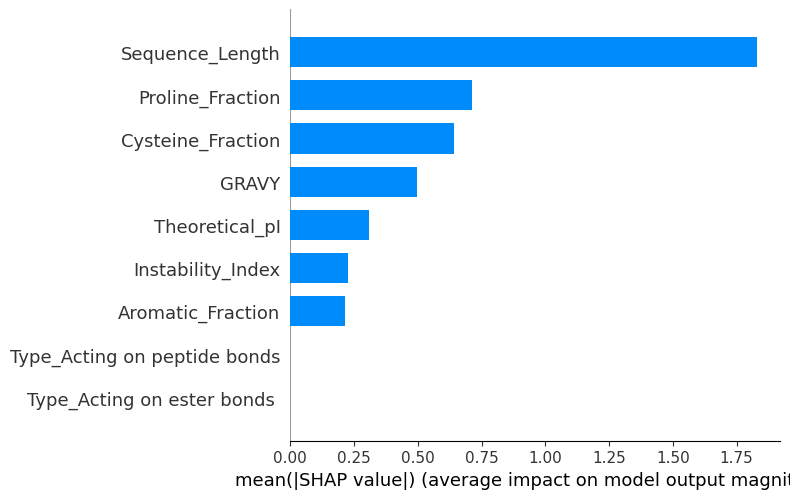

In [ ]:
shap.summary_plot(
    shap_values_pet,
    X_test,
    plot_type="bar"
)

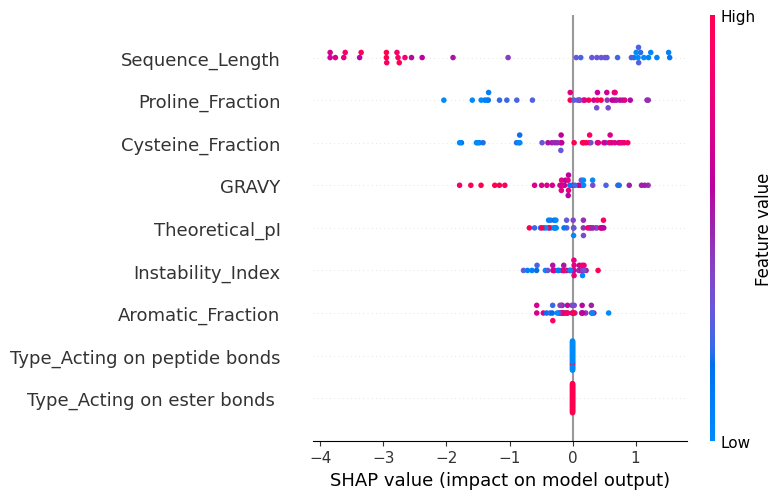

In [ ]:
shap.summary_plot(
    shap_values_pet,
    X_test
)

In [ ]:
shap_values_1A = {}
shap_explainers_1A = {}

for polymer in target_polymers:
    explainer = shap.TreeExplainer(final_models_1A[polymer])
    shap_values = explainer.shap_values(X_test)

    shap_explainers_1A[polymer] = explainer
    shap_values_1A[polymer] = shap_values

    print(
        polymer,
        "| X:", X_test.shape,
        "| SHAP:", shap_values.shape
    )

PET | X: (39, 9) | SHAP: (39, 9)
PHB | X: (39, 9) | SHAP: (39, 9)
PCL | X: (39, 9) | SHAP: (39, 9)
PBSA | X: (39, 9) | SHAP: (39, 9)
PBAT | X: (39, 9) | SHAP: (39, 9)
PLA | X: (39, 9) | SHAP: (39, 9)
PHA | X: (39, 9) | SHAP: (39, 9)
Nylon | X: (39, 9) | SHAP: (39, 9)


In [ ]:
shap_importance_1A = pd.DataFrame(
    {
        polymer: np.mean(
            np.abs(shap_values_1A[polymer]),
            axis=0
        )
        for polymer in target_polymers
    },
    index=X_test.columns
)

shap_importance_1A["Mean_Importance"] = shap_importance_1A.mean(axis=1)

shap_importance_1A = shap_importance_1A.sort_values(
    "Mean_Importance",
    ascending=False
)

print(shap_importance_1A.round(4))

                                 PET     PHB     PCL    PBSA    PBAT     PLA  \
Sequence_Length               1.8286  1.8735  0.9649  0.5667  0.9494  0.6650   
Proline_Fraction              0.7143  0.4636  0.3928  0.5952  0.7747  2.8978   
GRAVY                         0.4983  0.5969  0.6722  1.1147  0.8536  0.2959   
Theoretical_pI                0.3098  0.4022  0.3758  0.6762  0.7894  1.0421   
Cysteine_Fraction             0.6412  0.9678  0.5173  0.8409  1.0340  0.3507   
Instability_Index             0.2259  0.3653  0.3425  1.0546  0.7310  0.6437   
Aromatic_Fraction             0.2149  0.3234  0.3737  0.6398  0.7281  0.3291   
Type_Acting on ester bonds    0.0000  0.0000  0.0000  0.0000  0.0000  0.3859   
Type_Acting on peptide bonds  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   

                                 PHA   Nylon  Mean_Importance  
Sequence_Length               1.0587  1.1358           1.1303  
Proline_Fraction              0.8502  0.1686           0.8571  
GRAVY  

# MODEL 2B  

In [ ]:
import json
from collections import defaultdict

interpro_files = [
    "../processed/inter_pro_results1.json",
    "../processed/inter_pro_results2.json"
]

annotation_info = defaultdict(set)

for file in interpro_files:
    with open(file, "r") as f:
        data = json.load(f)

    for result in data["results"]:
        for match in result.get("matches", []):
            signature = match.get("signature", {})

            library = signature.get("signatureLibraryRelease", {}).get("library")
            accession = signature.get("accession")

            if library not in [
                "Pfam",
                "CATH-Gene3D",
                "PANTHER",
                "SUPERFAMILY",
                "NCBIFAM",
                "PIRSF",
                "PRINTS"
            ]:
                continue

            if accession is None:
                continue

            entry = signature.get("entry") or {}

            text = " ".join(
                str(x) for x in [
                    signature.get("name"),
                    signature.get("description"),
                    entry.get("name"),
                    entry.get("description")
                ] if x
            ).lower()

            annotation_info[(library, accession)].add(text)

target_patterns = [
    "petase",
    "pet hydrolase",
    "pet_hydrolase",
    "pet-hydrolase",
    "phb depolymerase",
    "phb_depoly",
    "phb de-polymerase",
    "esterase phb",
    "esterase_phb",
    "pha depolymerase",
    "pha_depoly",
    "polyhydroxyalkanoate depolymerase",
    "polyhydroxyalkanoate synthase",
    "pha/phb synthase",
    "pha phb synthase",
    "phb synthase",
    "phb depo",
    "phb_depo",
    "bh(et) hydrolase",
    "bishydroxyethyl terephthalate hydrolase",
    "bis(hydroxyethyl) terephthalate hydrolase"
]

safe_annotations = []
excluded_annotations = []

for key, descriptions in annotation_info.items():
    combined_text = " ".join(descriptions)

    matched_patterns = [
        pattern
        for pattern in target_patterns
        if pattern in combined_text
    ]

    if matched_patterns:
        excluded_annotations.append(
            (key, combined_text, matched_patterns)
        )
    else:
        safe_annotations.append(
            (key, combined_text)
        )

print("Total unique annotations:", len(annotation_info))
print("Safe annotations:", len(safe_annotations))
print("Excluded annotations:", len(excluded_annotations))

print("\nEXCLUDED:")
for item in sorted(excluded_annotations):
    print(item)

print("\nSAFE:")
for item in sorted(safe_annotations):
    print(item)

Total unique annotations: 126
Safe annotations: 112
Excluded annotations: 14

EXCLUDED:
(('NCBIFAM', 'NF050057'), 'e_dphamcl extracellular medium-chain-length polyhydroxyalkanoate depolymerase', ['polyhydroxyalkanoate depolymerase'])
(('NCBIFAM', 'NF050058'), 'e_dphascl_type1 extracellular catalytic domain type 1 short-chain-length polyhydroxyalkanoate depolymerase', ['polyhydroxyalkanoate depolymerase'])
(('NCBIFAM', 'NF050059'), 'e_dphascl_type2 extracellular catalytic domain type 2 short-chain-length polyhydroxyalkanoate depolymerase', ['polyhydroxyalkanoate depolymerase'])
(('NCBIFAM', 'NF050060'), 'e_nphascl extracellular native short-chain-length polyhydroxyalkanoate depolymerase phaz7', ['polyhydroxyalkanoate depolymerase'])
(('NCBIFAM', 'NF050089'), 'i_nphascl intracellular short-chain-length polyhydroxyalkanoate depolymerase', ['polyhydroxyalkanoate depolymerase'])
(('NCBIFAM', 'NF051441'), 'bishyethterphbdea bis(hydroxyethyl) terephthalate hydrolase', ['bis(hydroxyethyl) tere

In [ ]:
import json
from collections import defaultdict

interpro_files = [
    "../processed/inter_pro_results1.json",
    "../processed/inter_pro_results2.json"
]

annotation_proteins = defaultdict(set)

for file in interpro_files:
    with open(file, "r") as f:
        data = json.load(f)

    for result in data["results"]:
        protein_id = result["xref"][0]["name"]

        for match in result.get("matches", []):
            signature = match.get("signature", {})

            library = signature.get("signatureLibraryRelease", {}).get("library")
            accession = signature.get("accession")

            if library not in [
                "Pfam",
                "CATH-Gene3D",
                "PANTHER",
                "SUPERFAMILY",
                "NCBIFAM",
                "PIRSF",
                "PRINTS"
            ]:
                continue

            if accession is None:
                continue

            annotation_proteins[(library, accession)].add(protein_id)

frequency_results = []

for annotation, proteins in annotation_proteins.items():
    frequency_results.append(
        (
            annotation,
            len(proteins),
            len(proteins) / 188
        )
    )

frequency_results.sort(key=lambda x: x[1], reverse=True)

print("Total annotations:", len(frequency_results))
print()

for annotation, count, fraction in frequency_results:
    print(
        annotation,
        "| proteins:", count,
        "| percentage:", round(fraction * 100, 2)
    )

Total annotations: 126

('CATH-Gene3D', 'G3DSA:3.40.50.1820') | proteins: 168 | percentage: 89.36
('SUPERFAMILY', 'SSF53474') | proteins: 167 | percentage: 88.83
('PANTHER', 'PTHR22946') | proteins: 67 | percentage: 35.64
('Pfam', 'PF12740') | proteins: 65 | percentage: 34.57
('Pfam', 'PF10503') | proteins: 26 | percentage: 13.83
('PANTHER', 'PTHR43037') | proteins: 24 | percentage: 12.77
('NCBIFAM', 'NF050058') | proteins: 22 | percentage: 11.7
('NCBIFAM', 'TIGR01840') | proteins: 22 | percentage: 11.7
('CATH-Gene3D', 'G3DSA:2.60.40.10') | proteins: 20 | percentage: 10.64
('Pfam', 'PF01083') | proteins: 16 | percentage: 8.51
('Pfam', 'PF00041') | proteins: 16 | percentage: 8.51
('SUPERFAMILY', 'SSF49265') | proteins: 16 | percentage: 8.51
('PANTHER', 'PTHR48250') | proteins: 12 | percentage: 6.38
('PRINTS', 'PR00129') | proteins: 12 | percentage: 6.38
('NCBIFAM', 'NF050059') | proteins: 11 | percentage: 5.85
('PANTHER', 'PTHR42972') | proteins: 11 | percentage: 5.85
('Pfam', 'PF00561'

In [ ]:
import pandas as pd

annotation_rows = []

for annotation, proteins in annotation_proteins.items():
    library, accession = annotation

    descriptions = annotation_info.get(annotation, set())

    description = " | ".join(sorted(descriptions))

    annotation_rows.append({
        "Database": library,
        "Accession": accession,
        "Description": description,
        "Protein_Count": len(proteins),
        "Percentage": round(len(proteins) / 188 * 100, 2)
    })

annotation_df = pd.DataFrame(annotation_rows)

annotation_df = annotation_df.sort_values(
    "Protein_Count",
    ascending=False
).reset_index(drop=True)

annotation_df.head(40)

,Database,Accession,Description,Protein_Count,Percentage
0,CATH-Gene3D,G3DSA:3.40.50.1820,| alpha/beta hydrolase ab_hydrolase_fold alph...,168,89.36
1,SUPERFAMILY,SSF53474,| alpha/beta-hydrolases ab_hydrolase_fold alp...,167,88.83
2,PANTHER,PTHR22946,| dienelactone hydrolase domain-containing pr...,67,35.64
3,Pfam,PF12740,| petase pet hydrolase-like pet_hydrolase/cut...,65,34.57
4,Pfam,PF10503,| esterase_phb esterase phb depolymerase este...,26,13.83
5,PANTHER,PTHR43037,| unnamed product-related plant_biomass_hydro...,24,12.77
6,NCBIFAM,NF050058,e_dphascl_type1 extracellular catalytic domain...,22,11.70
7,NCBIFAM,TIGR01840,| esterase_phb phb depolymerase family estera...,22,11.70
8,CATH-Gene3D,G3DSA:2.60.40.10,| immunoglobulins ig-like_fold immunoglobulin...,20,10.64
9,Pfam,PF01083,| cutinase cutinase cutinase/axe cutinase/ace...,16,8.51


In [ ]:
redundant_groups = {
    "alpha_beta_hydrolase": [
        ("CATH-Gene3D", "G3DSA:3.40.50.1820"),
        ("SUPERFAMILY", "SSF53474"),
        ("Pfam", "PF00561"),
        ("PRINTS", "PR00111"),
        ("Pfam", "PF12697"),
        ("PANTHER", "PTHR34043")
    ],
    
    "fibronectin_type_III": [
        ("Pfam", "PF00041"),
        ("SUPERFAMILY", "SSF49265")
    ],
    
    "cutinase": [
        ("Pfam", "PF01083"),
        ("PRINTS", "PR00129"),
        ("PANTHER", "PTHR48250"),
        ("PANTHER", "PTHR33630")
    ],
    
    "beta_lactamase": [
        ("SUPERFAMILY", "SSF56601"),
        ("Pfam", "PF00144"),
        ("PANTHER", "PTHR43283"),
        ("CATH-Gene3D", "G3DSA:3.40.710.10")
    ]
}

for group, annotations in redundant_groups.items():
    print(group)
    for annotation in annotations:
        print("  ", annotation)

alpha_beta_hydrolase
   ('CATH-Gene3D', 'G3DSA:3.40.50.1820')
   ('SUPERFAMILY', 'SSF53474')
   ('Pfam', 'PF00561')
   ('PRINTS', 'PR00111')
   ('Pfam', 'PF12697')
   ('PANTHER', 'PTHR34043')
fibronectin_type_III
   ('Pfam', 'PF00041')
   ('SUPERFAMILY', 'SSF49265')
cutinase
   ('Pfam', 'PF01083')
   ('PRINTS', 'PR00129')
   ('PANTHER', 'PTHR48250')
   ('PANTHER', 'PTHR33630')
beta_lactamase
   ('SUPERFAMILY', 'SSF56601')
   ('Pfam', 'PF00144')
   ('PANTHER', 'PTHR43283')
   ('CATH-Gene3D', 'G3DSA:3.40.710.10')


In [ ]:
annotation_to_group = {}

for group_name, annotations in redundant_groups.items():
    for annotation in annotations:
        annotation_to_group[annotation] = group_name

print("Annotations mapped:", len(annotation_to_group))

for annotation, group_name in annotation_to_group.items():
    print(annotation, "->", group_name)

Annotations mapped: 16
('CATH-Gene3D', 'G3DSA:3.40.50.1820') -> alpha_beta_hydrolase
('SUPERFAMILY', 'SSF53474') -> alpha_beta_hydrolase
('Pfam', 'PF00561') -> alpha_beta_hydrolase
('PRINTS', 'PR00111') -> alpha_beta_hydrolase
('Pfam', 'PF12697') -> alpha_beta_hydrolase
('PANTHER', 'PTHR34043') -> alpha_beta_hydrolase
('Pfam', 'PF00041') -> fibronectin_type_III
('SUPERFAMILY', 'SSF49265') -> fibronectin_type_III
('Pfam', 'PF01083') -> cutinase
('PRINTS', 'PR00129') -> cutinase
('PANTHER', 'PTHR48250') -> cutinase
('PANTHER', 'PTHR33630') -> cutinase
('SUPERFAMILY', 'SSF56601') -> beta_lactamase
('Pfam', 'PF00144') -> beta_lactamase
('PANTHER', 'PTHR43283') -> beta_lactamase
('CATH-Gene3D', 'G3DSA:3.40.710.10') -> beta_lactamase


In [ ]:
import pandas as pd

protein_ids = sorted({
    protein
    for proteins in annotation_proteins.values()
    for protein in proteins
})

consolidated_features = pd.DataFrame(
    0,
    index=protein_ids,
    columns=list(redundant_groups.keys()),
    dtype=int
)

for group_name, annotations in redundant_groups.items():
    proteins_with_group = set()

    for annotation in annotations:
        proteins_with_group.update(
            annotation_proteins.get(annotation, set())
        )

    consolidated_features.loc[
        list(proteins_with_group),
        group_name
    ] = 1

print("Shape:", consolidated_features.shape)
print()
print(consolidated_features.sum().sort_values(ascending=False))

Shape: (188, 4)

alpha_beta_hydrolase    168
fibronectin_type_III     16
cutinase                 16
beta_lactamase            5
dtype: int64


In [ ]:
print("Total annotation_proteins:", len(annotation_proteins))
print("Total safe_annotations:", len(safe_annotations))

annotations_with_proteins = [
    annotation
    for annotation in safe_annotations
    if annotation in annotation_proteins
    and len(annotation_proteins[annotation]) > 0
]

print("Safe annotations with proteins:", len(annotations_with_proteins))
print("Safe annotations without proteins:", len(safe_annotations) - len(annotations_with_proteins))

Total annotation_proteins: 238
Total safe_annotations: 112
Safe annotations with proteins: 0
Safe annotations without proteins: 112


In [ ]:
feature_counts = candidate_features.sum()

selected_by_frequency = feature_counts[
    feature_counts >= 5
].index

frequency_filtered_features = candidate_features[
    selected_by_frequency
].copy()

print("Features before filtering:", candidate_features.shape[1])
print("Features after filtering:", frequency_filtered_features.shape[1])

print("\nSelected features:")
print(
    frequency_filtered_features.sum()
    .sort_values(ascending=False)
)

Features before filtering: 116
Features after filtering: 4

Selected features:
alpha_beta_hydrolase    168
fibronectin_type_III     16
cutinase                 16
beta_lactamase            5
dtype: int64


In [ ]:
target_explicit_annotations = {
    ("CATH-Gene3D", "G3DSA:3.40.50.1820"),
    ("NCBIFAM", "NF050057"),
    ("NCBIFAM", "NF050058"),
    ("NCBIFAM", "NF050059"),
    ("NCBIFAM", "NF050060"),
    ("NCBIFAM", "NF050089"),
    ("NCBIFAM", "NF051441"),
    ("NCBIFAM", "TIGR01840"),
    ("NCBIFAM", "TIGR01849"),
    ("NCBIFAM", "TIGR02240"),
    ("NCBIFAM", "TIGR03056"),
    ("PANTHER", "PTHR10272"),
    ("PANTHER", "PTHR33428"),
    ("PANTHER", "PTHR34043"),
    ("PANTHER", "PTHR36837"),
    ("PANTHER", "PTHR43037"),
    ("PANTHER", "PTHR43194"),
    ("PANTHER", "PTHR43433"),
    ("PANTHER", "PTHR45856"),
    ("PANTHER", "PTHR46438"),
    ("PIRSF", "PIRSF020818"),
    ("PRINTS", "PR00111"),
    ("Pfam", "PF00561"),
    ("Pfam", "PF03403"),
    ("Pfam", "PF06850"),
    ("Pfam", "PF07819"),
    ("Pfam", "PF07859"),
    ("Pfam", "PF10503"),
    ("Pfam", "PF12146"),
    ("Pfam", "PF12697"),
    ("Pfam", "PF12740"),
    ("SUPERFAMILY", "SSF53474")
}

In [ ]:
safe_annotations = [
    annotation
    for annotation in annotation_proteins
    if annotation not in target_explicit_annotations
    and annotation not in annotation_to_group
]

print("Total annotations:", len(annotation_proteins))
print("Target-explicit removed:", len(target_explicit_annotations))
print("Redundant raw annotations removed:", len(annotation_to_group))
print("Safe non-redundant raw annotations:", len(safe_annotations))

Total annotations: 126
Target-explicit removed: 32
Redundant raw annotations removed: 16
Safe non-redundant raw annotations: 84


In [ ]:
candidate_features = consolidated_features.copy()

for annotation in safe_annotations:
    feature_name = f"{annotation[0]}_{annotation[1]}"
    
    proteins = annotation_proteins[annotation]
    
    candidate_features[feature_name] = 0
    candidate_features.loc[list(proteins), feature_name] = 1

print("Candidate matrix shape:", candidate_features.shape)

feature_counts = candidate_features.sum().sort_values(ascending=False)

print("\nFeatures occurring in each number of proteins:")
print(feature_counts.value_counts().sort_index())

Candidate matrix shape: (188, 116)

Features occurring in each number of proteins:
0      112
5        1
16       2
168      1
Name: count, dtype: int64


C:\Users\shaza\AppData\Local\Temp\ipykernel_21520\3945662497.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  candidate_features[feature_name] = 0


In [ ]:
selected_features = feature_counts[
    feature_counts >= 5
].index

frequency_filtered_features = candidate_features[
    selected_features
].copy()

print("Features after frequency filtering:",
      frequency_filtered_features.shape[1])

print("\nSelected features:")
print(
    frequency_filtered_features.sum()
    .sort_values(ascending=False)
)

Features after frequency filtering: 10

Selected features:
alpha_beta_hydrolase            168
PANTHER_PTHR22946                67
CATH-Gene3D_G3DSA:2.60.40.10     20
cutinase                         16
fibronectin_type_III             16
PANTHER_PTHR42972                11
Pfam_PF00326                      7
PANTHER_PTHR43798                 6
beta_lactamase                    5
Pfam_PF24708                      5
dtype: int64


In [ ]:
import numpy as np
import pandas as pd

X_candidates = frequency_filtered_features.copy()

correlation_matrix = X_candidates.corr(method="pearson")

print("Correlation matrix:")
display(correlation_matrix.round(3))

Correlation matrix:


,alpha_beta_hydrolase,PANTHER_PTHR22946,CATH-Gene3D_G3DSA:2.60.40.10,cutinase,fibronectin_type_III,PANTHER_PTHR42972,Pfam_PF00326,PANTHER_PTHR43798,beta_lactamase,Pfam_PF24708
alpha_beta_hydrolase,1.000,0.257,0.119,0.105,0.105,0.086,0.068,0.063,-0.479,0.057
PANTHER_PTHR22946,0.257,1.000,-0.257,-0.227,-0.227,-0.186,0.030,-0.135,-0.123,-0.123
CATH-Gene3D_G3DSA:2.60.40.10,0.119,-0.257,1.000,-0.105,0.884,0.502,0.023,-0.063,-0.057,-0.057
cutinase,0.105,-0.227,-0.105,1.000,-0.093,-0.076,-0.060,-0.055,-0.050,-0.050
fibronectin_type_III,0.105,-0.227,0.884,-0.093,1.000,0.574,0.041,-0.055,-0.050,-0.050
PANTHER_PTHR42972,0.086,-0.186,0.502,-0.076,0.574,1.000,0.430,-0.045,-0.041,-0.041
Pfam_PF00326,0.068,0.030,0.023,-0.060,0.041,0.430,1.000,-0.036,-0.033,-0.033
PANTHER_PTHR43798,0.063,-0.135,-0.063,-0.055,-0.055,-0.045,-0.036,1.000,-0.030,-0.030
beta_lactamase,-0.479,-0.123,-0.057,-0.050,-0.050,-0.041,-0.033,-0.030,1.000,-0.027
Pfam_PF24708,0.057,-0.123,-0.057,-0.050,-0.050,-0.041,-0.033,-0.030,-0.027,1.000


In [ ]:
pairs = []

columns = correlation_matrix.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        pairs.append({
            "Feature_1": columns[i],
            "Feature_2": columns[j],
            "Correlation": correlation_matrix.iloc[i, j],
            "Absolute_Correlation": abs(correlation_matrix.iloc[i, j])
        })

correlation_pairs = pd.DataFrame(pairs).sort_values(
    "Absolute_Correlation",
    ascending=False
)

display(correlation_pairs.head(20))

,Feature_1,Feature_2,Correlation,Absolute_Correlation
18,CATH-Gene3D_G3DSA:2.60.40.10,fibronectin_type_III,0.883966,0.883966
30,fibronectin_type_III,PANTHER_PTHR42972,0.573708,0.573708
19,CATH-Gene3D_G3DSA:2.60.40.10,PANTHER_PTHR42972,0.502010,0.502010
7,alpha_beta_hydrolase,beta_lactamase,-0.479070,0.479070
35,PANTHER_PTHR42972,Pfam_PF00326,0.429766,0.429766
9,PANTHER_PTHR22946,CATH-Gene3D_G3DSA:2.60.40.10,-0.256747,0.256747
0,alpha_beta_hydrolase,PANTHER_PTHR22946,0.256747,0.256747
10,PANTHER_PTHR22946,cutinase,-0.226955,0.226955
11,PANTHER_PTHR22946,fibronectin_type_III,-0.226955,0.226955
12,PANTHER_PTHR22946,PANTHER_PTHR42972,-0.185504,0.185504


In [ ]:
duplicate_pairs = []

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        if X_candidates[columns[i]].equals(X_candidates[columns[j]]):
            duplicate_pairs.append(
                (columns[i], columns[j])
            )

print("Exact duplicate feature pairs:")
print(duplicate_pairs)

Exact duplicate feature pairs:
[]


In [ ]:
selected_annotation_features = candidate_features[
    [
        "alpha_beta_hydrolase",
        "PANTHER_PTHR22946",
        "CATH-Gene3D_G3DSA:2.60.40.10",
        "cutinase",
        "fibronectin_type_III",
        "PANTHER_PTHR42972",
        "Pfam_PF00326",
        "PANTHER_PTHR43798",
        "beta_lactamase",
        "Pfam_PF24708"
    ]
].copy()

print("Selected annotation matrix shape:", selected_annotation_features.shape)
print(selected_annotation_features.columns.tolist())

Selected annotation matrix shape: (188, 10)
['alpha_beta_hydrolase', 'PANTHER_PTHR22946', 'CATH-Gene3D_G3DSA:2.60.40.10', 'cutinase', 'fibronectin_type_III', 'PANTHER_PTHR42972', 'Pfam_PF00326', 'PANTHER_PTHR43798', 'beta_lactamase', 'Pfam_PF24708']


In [ ]:
model1B_features = pd.concat(
    [
        X_train.copy(),
        selected_annotation_features.loc[X_train.index].copy()
    ],
    axis=1
)

model1B_test_features = pd.concat(
    [
        X_test.copy(),
        selected_annotation_features.loc[X_test.index].copy()
    ],
    axis=1
)

print("Model 1B train shape:", model1B_features.shape)
print("Model 1B test shape:", model1B_test_features.shape)
print("Missing train values:", model1B_features.isna().sum().sum())
print("Missing test values:", model1B_test_features.isna().sum().sum())

Model 1B train shape: (149, 19)
Model 1B test shape: (39, 19)
Missing train values: 0
Missing test values: 0


CV for Model 1B

In [ ]:
import numpy as np
from scipy.optimize import milp, LinearConstraint, Bounds

n_folds = 3

group_names = cv_group_data["group"].to_numpy()
group_sizes = cv_group_data["group_size"].to_numpy(dtype=float)
group_labels = cv_group_data[target_polymers].to_numpy(dtype=float)

n_groups = len(group_names)
n_labels = len(target_polymers)

print("Number of groups:", n_groups)
print("Number of polymers:", n_labels)
print("Training proteins represented by groups:", int(group_sizes.sum()))

assert n_groups == 122
assert group_sizes.sum() == 149

target_fold_size = group_sizes.sum() / n_folds
overall_label_counts = group_labels.sum(axis=0)
target_label_counts = overall_label_counts / n_folds

n_x = n_groups * n_folds
n_d = n_folds * (1 + n_labels)
n_vars = n_x + n_d

def x_index(group_number, fold_number):
    return group_number * n_folds + fold_number

def d_index(fold_number, variable_number):
    return n_x + fold_number * (1 + n_labels) + variable_number

objective = np.zeros(n_vars)

objective[n_x:] = 1.0

for fold_number in range(n_folds):
    objective[d_index(fold_number, 0)] = 1.0 / target_fold_size

    for label_number in range(n_labels):
        objective[d_index(fold_number, 1 + label_number)] = (
            1.0 / target_label_counts[label_number]
        )

integrality = np.zeros(n_vars)
integrality[:n_x] = 1

lower_bounds = np.zeros(n_vars)
upper_bounds = np.full(n_vars, np.inf)

upper_bounds[:n_x] = 1

constraint_rows = []
constraints_lb = []
constraints_ub = []

for group_number in range(n_groups):
    row = np.zeros(n_vars)

    for fold_number in range(n_folds):
        row[x_index(group_number, fold_number)] = 1

    constraint_rows.append(row)
    constraints_lb.append(1)
    constraints_ub.append(1)

for fold_number in range(n_folds):

    for label_number in range(n_labels):
        row = np.zeros(n_vars)

        for group_number in range(n_groups):
            row[x_index(group_number, fold_number)] = group_labels[group_number, label_number]

        constraint_rows.append(row)
        constraints_lb.append(1)
        constraints_ub.append(np.inf)

    for label_number in range(n_labels):
        row = np.zeros(n_vars)

        for group_number in range(n_groups):
            row[x_index(group_number, fold_number)] = (
                group_sizes[group_number] - group_labels[group_number, label_number]
            )

        constraint_rows.append(row)
        constraints_lb.append(1)
        constraints_ub.append(np.inf)

for fold_number in range(n_folds):

    row_base = np.zeros(n_vars)

    for group_number in range(n_groups):
        row_base[x_index(group_number, fold_number)] = group_sizes[group_number]

    deviation_variable = d_index(fold_number, 0)

    row = row_base.copy()
    row[deviation_variable] = -1

    constraint_rows.append(row)
    constraints_lb.append(-np.inf)
    constraints_ub.append(target_fold_size)

    row = -row_base.copy()
    row[deviation_variable] = -1

    constraint_rows.append(row)
    constraints_lb.append(-np.inf)
    constraints_ub.append(-target_fold_size)

for fold_number in range(n_folds):

    for label_number in range(n_labels):

        row_base = np.zeros(n_vars)

        for group_number in range(n_groups):
            row_base[x_index(group_number, fold_number)] = group_labels[group_number, label_number]

        deviation_variable = d_index(fold_number, 1 + label_number)
        target = target_label_counts[label_number]

        row = row_base.copy()
        row[deviation_variable] = -1

        constraint_rows.append(row)
        constraints_lb.append(-np.inf)
        constraints_ub.append(target)

        row = -row_base.copy()
        row[deviation_variable] = -1

        constraint_rows.append(row)
        constraints_lb.append(-np.inf)
        constraints_ub.append(-target)

constraint_matrix = np.vstack(constraint_rows)

constraints = LinearConstraint(
    constraint_matrix,
    np.array(constraints_lb),
    np.array(constraints_ub)
)

result = milp(
    c=objective,
    integrality=integrality,
    bounds=Bounds(lower_bounds, upper_bounds),
    constraints=constraints
)

print("\nMILP success:", result.success)
print("MILP message:", result.message)
print("MILP objective:", result.fun)

Number of groups: 122
Number of polymers: 8
Training proteins represented by groups: 149

MILP success: True
MILP message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
MILP objective: 2.6802069821168106


In [ ]:
for fold in range(n_folds):
    fold_groups = [
        group for group, assigned_fold in cv_fold_assignments.items()
        if assigned_fold == fold
    ]

    fold_indices = [
        i for i, group in enumerate(group_names)
        if group in fold_groups
    ]

    fold_size = group_sizes[fold_indices].sum()

    print(f"\nFold {fold + 1}")
    print("Proteins:", int(fold_size))

    for j, polymer in enumerate(target_polymers):
        positives = group_labels[fold_indices, j].sum()
        negatives = fold_size - positives

        print(
            polymer,
            "| positives:", int(positives),
            "| negatives:", int(negatives)
        )


Fold 1
Proteins: 49
PET | positives: 18 | negatives: 31
PHB | positives: 14 | negatives: 35
PCL | positives: 11 | negatives: 38
PBSA | positives: 6 | negatives: 43
PBAT | positives: 4 | negatives: 45
PLA | positives: 3 | negatives: 46
PHA | positives: 2 | negatives: 47
Nylon | positives: 2 | negatives: 47

Fold 2
Proteins: 50
PET | positives: 19 | negatives: 31
PHB | positives: 13 | negatives: 37
PCL | positives: 12 | negatives: 38
PBSA | positives: 5 | negatives: 45
PBAT | positives: 5 | negatives: 45
PLA | positives: 3 | negatives: 47
PHA | positives: 2 | negatives: 48
Nylon | positives: 1 | negatives: 49

Fold 3
Proteins: 50
PET | positives: 19 | negatives: 31
PHB | positives: 13 | negatives: 37
PCL | positives: 11 | negatives: 39
PBSA | positives: 5 | negatives: 45
PBAT | positives: 5 | negatives: 45
PLA | positives: 4 | negatives: 46
PHA | positives: 2 | negatives: 48
Nylon | positives: 4 | negatives: 46


In [ ]:
for f in range(n_folds):
    print(f"\nFold {f + 1}")

    for j, polymer in enumerate(target_polymers):
        positives = 0
        total = 0

        for g in range(n_groups):
            if group_fold[group_names[g]] == f:
                positives += int(group_labels[g, j])
                total += int(group_sizes[g])

        negatives = total - positives

        print(
            polymer,
            "| positives:", positives,
            "| negatives:", negatives
        )


Fold 1
PET | positives: 18 | negatives: 31
PHB | positives: 14 | negatives: 35
PCL | positives: 11 | negatives: 38
PBSA | positives: 6 | negatives: 43
PBAT | positives: 4 | negatives: 45
PLA | positives: 3 | negatives: 46
PHA | positives: 2 | negatives: 47
Nylon | positives: 2 | negatives: 47

Fold 2
PET | positives: 19 | negatives: 31
PHB | positives: 13 | negatives: 37
PCL | positives: 12 | negatives: 38
PBSA | positives: 5 | negatives: 45
PBAT | positives: 5 | negatives: 45
PLA | positives: 3 | negatives: 47
PHA | positives: 2 | negatives: 48
Nylon | positives: 1 | negatives: 49

Fold 3
PET | positives: 19 | negatives: 31
PHB | positives: 13 | negatives: 37
PCL | positives: 11 | negatives: 39
PBSA | positives: 5 | negatives: 45
PBAT | positives: 5 | negatives: 45
PLA | positives: 4 | negatives: 46
PHA | positives: 2 | negatives: 48
Nylon | positives: 4 | negatives: 46


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
import numpy as np
import pandas as pd

cv_results_1B = []

for fold in range(n_folds):

    validation_proteins = []

    for g in range(n_groups):
        if group_fold[group_names[g]] == fold:
            validation_proteins.extend(
                protein_groups[
                    protein_groups["group"] == group_names[g]
                ]["protein_id"].tolist()
            )

    validation_proteins = set(validation_proteins)

    train_proteins = set(X_train.index) - validation_proteins

    train_idx = X_train.index.isin(train_proteins)
    val_idx = X_train.index.isin(validation_proteins)

    X_fold_train = X_train.loc[train_idx]
    X_fold_val = X_train.loc[val_idx]

    print(f"\nFold {fold + 1}")
    print("Training proteins:", len(X_fold_train))
    print("Validation proteins:", len(X_fold_val))

    for polymer in target_polymers:

        y_fold_train = y_train.loc[X_fold_train.index, polymer].to_numpy()
        y_fold_val = y_train.loc[X_fold_val.index, polymer].to_numpy()

        n_positive = np.sum(y_fold_train == 1)
        n_negative = np.sum(y_fold_train == 0)

        scale_pos_weight = n_negative / n_positive

        model = XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        sample_weights = np.where(
            y_fold_train == 1,
            scale_pos_weight,
            1.0
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            sample_weight=sample_weights
        )

        probabilities = model.predict_proba(X_fold_val)[:, 1]

        pr_auc = average_precision_score(
            y_fold_val,
            probabilities
        )

        roc_auc = roc_auc_score(
            y_fold_val,
            probabilities
        )

        cv_results_1B.append({
            "Fold": fold + 1,
            "Polymer": polymer,
            "PR_AUC": pr_auc,
            "ROC_AUC": roc_auc,
            "Validation_Positive": int(np.sum(y_fold_val == 1)),
            "Validation_Negative": int(np.sum(y_fold_val == 0))
        })

        print(
            polymer,
            "| PR-AUC:", round(pr_auc, 4),
            "| ROC-AUC:", round(roc_auc, 4)
        )

cv_results_1B = pd.DataFrame(cv_results_1B)

print("\nModel 1B CV complete.")
print("Number of results:", len(cv_results_1B))


Fold 1
Training proteins: 100
Validation proteins: 49
PET | PR-AUC: 0.7839 | ROC-AUC: 0.7885
PHB | PR-AUC: 0.6584 | ROC-AUC: 0.7418
PCL | PR-AUC: 0.3516 | ROC-AUC: 0.6926
PBSA | PR-AUC: 0.2777 | ROC-AUC: 0.7248
PBAT | PR-AUC: 0.2012 | ROC-AUC: 0.6889
PLA | PR-AUC: 0.2516 | ROC-AUC: 0.7174
PHA | PR-AUC: 0.2778 | ROC-AUC: 0.9043
Nylon | PR-AUC: 0.5 | ROC-AUC: 0.9681

Fold 2
Training proteins: 99
Validation proteins: 50
PET | PR-AUC: 0.6948 | ROC-AUC: 0.8098
PHB | PR-AUC: 0.7592 | ROC-AUC: 0.8482
PCL | PR-AUC: 0.3561 | ROC-AUC: 0.5482
PBSA | PR-AUC: 0.1844 | ROC-AUC: 0.5778
PBAT | PR-AUC: 0.1164 | ROC-AUC: 0.5111
PLA | PR-AUC: 0.5764 | ROC-AUC: 0.6738
PHA | PR-AUC: 0.6429 | ROC-AUC: 0.9479
Nylon | PR-AUC: 0.0455 | ROC-AUC: 0.5714

Fold 3
Training proteins: 99
Validation proteins: 50
PET | PR-AUC: 0.8906 | ROC-AUC: 0.9253
PHB | PR-AUC: 0.8318 | ROC-AUC: 0.9262
PCL | PR-AUC: 0.4785 | ROC-AUC: 0.7028
PBSA | PR-AUC: 0.3087 | ROC-AUC: 0.6089
PBAT | PR-AUC: 0.147 | ROC-AUC: 0.64
PLA | PR-AUC: 

In [ ]:
model1B_summary = (
    cv_results_1B
    .groupby("Polymer")
    .agg(
        Mean_PR_AUC=("PR_AUC", "mean"),
        SD_PR_AUC=("PR_AUC", "std"),
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        SD_ROC_AUC=("ROC_AUC", "std")
    )
    .reset_index()
)

print(model1B_summary.round(4))

  Polymer  Mean_PR_AUC  SD_PR_AUC  Mean_ROC_AUC  SD_ROC_AUC
0   Nylon       0.2537     0.2296        0.7795      0.1990
1    PBAT       0.1549     0.0429        0.6133      0.0918
2    PBSA       0.2569     0.0647        0.6372      0.0775
3     PCL       0.3954     0.0720        0.6479      0.0864
4     PET       0.7897     0.0980        0.8412      0.0736
5     PHA       0.3271     0.2942        0.7354      0.3309
6     PHB       0.7498     0.0871        0.8388      0.0925
7     PLA       0.4149     0.1624        0.7644      0.1213


In [ ]:
print(
    "Model 1B Mean PR-AUC:",
    round(cv_results_1B["PR_AUC"].mean(), 4)
)

print(
    "Model 1B Mean ROC-AUC:",
    round(cv_results_1B["ROC_AUC"].mean(), 4)
)

print(
    "Model 1B PR-AUC SD:",
    round(cv_results_1B["PR_AUC"].std(), 4)
)

print(
    "Model 1B ROC-AUC SD:",
    round(cv_results_1B["ROC_AUC"].std(), 4)
)

Model 1B Mean PR-AUC: 0.4178
Model 1B Mean ROC-AUC: 0.7322
Model 1B PR-AUC SD: 0.2576
Model 1B ROC-AUC SD: 0.1574


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
import pandas as pd

final_models_1B = {}
test_probabilities_1B = {}
test_results_1B = []

for polymer in target_polymers:

    y_train_polymer = y_train[polymer].to_numpy()
    y_test_polymer = y_test[polymer].to_numpy()

    n_positive = np.sum(y_train_polymer == 1)
    n_negative = np.sum(y_train_polymer == 0)

    scale_pos_weight = n_negative / n_positive

    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    sample_weights = np.where(
        y_train_polymer == 1,
        scale_pos_weight,
        1.0
    )

    model.fit(
        X_train,
        y_train_polymer,
        sample_weight=sample_weights
    )

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    pr_auc = average_precision_score(
        y_test_polymer,
        probabilities
    )

    roc_auc = roc_auc_score(
        y_test_polymer,
        probabilities
    )

    precision = precision_score(
        y_test_polymer,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test_polymer,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test_polymer,
        predictions,
        zero_division=0
    )

    cm = confusion_matrix(
        y_test_polymer,
        predictions
    )

    final_models_1B[polymer] = model
    test_probabilities_1B[polymer] = probabilities

    test_results_1B.append({
        "Polymer": polymer,
        "PR_AUC": pr_auc,
        "ROC_AUC": roc_auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Test_Positive": int(np.sum(y_test_polymer == 1)),
        "Test_Negative": int(np.sum(y_test_polymer == 0)),
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })

    print(
        polymer,
        "| PR-AUC:", round(pr_auc, 4),
        "| ROC-AUC:", round(roc_auc, 4),
        "| Precision:", round(precision, 4),
        "| Recall:", round(recall, 4),
        "| F1:", round(f1, 4)
    )

test_results_1B = pd.DataFrame(test_results_1B)

print("\nFinal Model 1B test evaluation complete.")

PET | PR-AUC: 0.8344 | ROC-AUC: 0.8222 | Precision: 0.6667 | Recall: 0.6667 | F1: 0.6667
PHB | PR-AUC: 0.85 | ROC-AUC: 0.8862 | Precision: 0.6667 | Recall: 0.8 | F1: 0.7273
PCL | PR-AUC: 0.6066 | ROC-AUC: 0.8667 | Precision: 0.75 | Recall: 0.6667 | F1: 0.7059
PBSA | PR-AUC: 0.0904 | ROC-AUC: 0.3214 | Precision: 0.0 | Recall: 0.0 | F1: 0.0
PBAT | PR-AUC: 0.378 | ROC-AUC: 0.8929 | Precision: 0.0 | Recall: 0.0 | F1: 0.0
PLA | PR-AUC: 0.1288 | ROC-AUC: 0.7297 | Precision: 0.0 | Recall: 0.0 | F1: 0.0
PHA | PR-AUC: 0.5294 | ROC-AUC: 0.5676 | Precision: 1.0 | Recall: 0.5 | F1: 0.6667
Nylon | PR-AUC: 0.6111 | ROC-AUC: 0.9054 | Precision: 0.5 | Recall: 0.5 | F1: 0.5

Final Model 1B test evaluation complete.


Threshold Tuning

In [ ]:
from xgboost import XGBClassifier
import numpy as np
import pandas as pd

oof_probabilities_1B = {
    polymer: np.zeros(len(X_train))
    for polymer in target_polymers
}

oof_results_1B = []

for fold in range(n_folds):

    validation_proteins = []

    for g in range(n_groups):
        if group_fold[group_names[g]] == fold:
            validation_proteins.extend(
                protein_groups[
                    protein_groups["group"] == group_names[g]
                ]["protein_id"].tolist()
            )

    validation_proteins = set(validation_proteins)

    train_proteins = set(X_train.index) - validation_proteins

    train_idx = X_train.index.isin(train_proteins)
    val_idx = X_train.index.isin(validation_proteins)

    X_fold_train = X_train.loc[train_idx]
    X_fold_val = X_train.loc[val_idx]

    for polymer in target_polymers:

        y_fold_train = y_train.loc[X_fold_train.index, polymer].to_numpy()
        y_fold_val = y_train.loc[X_fold_val.index, polymer].to_numpy()

        n_positive = np.sum(y_fold_train == 1)
        n_negative = np.sum(y_fold_train == 0)

        scale_pos_weight = n_negative / n_positive

        model = XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        sample_weights = np.where(
            y_fold_train == 1,
            scale_pos_weight,
            1.0
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            sample_weight=sample_weights
        )

        probabilities = model.predict_proba(X_fold_val)[:, 1]

        oof_probabilities_1B[polymer][val_idx] = probabilities

        oof_results_1B.append({
            "Fold": fold + 1,
            "Polymer": polymer,
            "Validation_Positive": int(np.sum(y_fold_val == 1)),
            "Validation_Negative": int(np.sum(y_fold_val == 0))
        })

print("OOF probability generation complete.")

OOF probability generation complete.


In [ ]:
from sklearn.metrics import precision_recall_curve

thresholds_1B = {}

for polymer in target_polymers:

    y_true = y_train[polymer].to_numpy()
    probabilities = oof_probabilities_1B[polymer]

    precision, recall, threshold_values = precision_recall_curve(
        y_true,
        probabilities
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_index = np.argmax(f1_scores)

    thresholds_1B[polymer] = threshold_values[best_index]

    print(
        polymer,
        "| threshold:", round(thresholds_1B[polymer], 4),
        "| OOF Precision:", round(precision[best_index], 4),
        "| OOF Recall:", round(recall[best_index], 4),
        "| OOF F1:", round(f1_scores[best_index], 4)
    )

print("\nThreshold selection complete.")

PET | threshold: 0.3489 | OOF Precision: 0.6667 | OOF Recall: 0.7857 | OOF F1: 0.7213
PHB | threshold: 0.1364 | OOF Precision: 0.5593 | OOF Recall: 0.825 | OOF F1: 0.6667
PCL | threshold: 0.2728 | OOF Precision: 0.38 | OOF Recall: 0.5588 | OOF F1: 0.4524
PBSA | threshold: 0.1638 | OOF Precision: 0.2759 | OOF Recall: 0.5 | OOF F1: 0.3556
PBAT | threshold: 0.0167 | OOF Precision: 0.1354 | OOF Recall: 0.9286 | OOF F1: 0.2364
PLA | threshold: 0.1973 | OOF Precision: 0.3571 | OOF Recall: 0.5 | OOF F1: 0.4167
PHA | threshold: 0.3572 | OOF Precision: 0.5 | OOF Recall: 0.3333 | OOF F1: 0.4
Nylon | threshold: 0.0247 | OOF Precision: 0.2069 | OOF Recall: 0.8571 | OOF F1: 0.3333

Threshold selection complete.


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
import pandas as pd

threshold_test_results_1B = []

for polymer in target_polymers:

    y_true = y_test[polymer].to_numpy()
    probabilities = test_probabilities_1B[polymer]
    threshold = thresholds_1B[polymer]

    predictions = (probabilities >= threshold).astype(int)

    precision = precision_score(
        y_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0
    )

    cm = confusion_matrix(
        y_true,
        predictions
    )

    threshold_test_results_1B.append({
        "Polymer": polymer,
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Test_Positive": int(np.sum(y_true == 1)),
        "Test_Negative": int(np.sum(y_true == 0)),
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })

threshold_test_results_1B = pd.DataFrame(
    threshold_test_results_1B
)

print(
    threshold_test_results_1B.round(4).to_string(index=False)
)

Polymer  Threshold  Precision  Recall     F1  Test_Positive  Test_Negative  TN  FP  FN  TP
    PET     0.3489     0.6111  0.7333 0.6667             15             24  17   7   4  11
    PHB     0.1364     0.4737  0.9000 0.6207             10             29  19  10   1   9
    PCL     0.2728     0.5833  0.7778 0.6667              9             30  25   5   2   7
   PBSA     0.1638     0.0000  0.0000 0.0000              4             35  32   3   4   0
   PBAT     0.0167     0.2000  1.0000 0.3333              4             35  19  16   0   4
    PLA     0.1973     0.0000  0.0000 0.0000              2             37  36   1   2   0
    PHA     0.3572     1.0000  0.5000 0.6667              2             37  37   0   1   1
  Nylon     0.0247     0.1429  0.5000 0.2222              2             37  31   6   1   1


SHAP ANALYSIS FOR MODEL 1B

In [ ]:
print("Model 1B features shape:", model1B_features.shape)

print("\nModel 1B feature columns:")
print(model1B_features.columns.tolist())

print("\nModel 1B test features shape:", model1B_test_features.shape)

print("\nModel 1B test feature columns:")
print(model1B_test_features.columns.tolist())

Model 1B features shape: (149, 19)

Model 1B feature columns:
['Sequence_Length', 'GRAVY', 'Aromatic_Fraction', 'Proline_Fraction', 'Cysteine_Fraction', 'Theoretical_pI', 'Instability_Index', 'Type_Acting on ester bonds ', 'Type_Acting on peptide bonds', 'alpha_beta_hydrolase', 'PANTHER_PTHR22946', 'CATH-Gene3D_G3DSA:2.60.40.10', 'cutinase', 'fibronectin_type_III', 'PANTHER_PTHR42972', 'Pfam_PF00326', 'PANTHER_PTHR43798', 'beta_lactamase', 'Pfam_PF24708']

Model 1B test features shape: (39, 19)

Model 1B test feature columns:
['Sequence_Length', 'GRAVY', 'Aromatic_Fraction', 'Proline_Fraction', 'Cysteine_Fraction', 'Theoretical_pI', 'Instability_Index', 'Type_Acting on ester bonds ', 'Type_Acting on peptide bonds', 'alpha_beta_hydrolase', 'PANTHER_PTHR22946', 'CATH-Gene3D_G3DSA:2.60.40.10', 'cutinase', 'fibronectin_type_III', 'PANTHER_PTHR42972', 'Pfam_PF00326', 'PANTHER_PTHR43798', 'beta_lactamase', 'Pfam_PF24708']


In [ ]:
print(model1B_features.shape)
print(model1B_test_features.shape)

print(model1B_features.columns.tolist())
print(model1B_test_features.columns.tolist())

print(model1B_features.index.equals(model1B_test_features.index))

(149, 19)
(39, 19)
['Sequence_Length', 'GRAVY', 'Aromatic_Fraction', 'Proline_Fraction', 'Cysteine_Fraction', 'Theoretical_pI', 'Instability_Index', 'Type_Acting on ester bonds ', 'Type_Acting on peptide bonds', 'alpha_beta_hydrolase', 'PANTHER_PTHR22946', 'CATH-Gene3D_G3DSA:2.60.40.10', 'cutinase', 'fibronectin_type_III', 'PANTHER_PTHR42972', 'Pfam_PF00326', 'PANTHER_PTHR43798', 'beta_lactamase', 'Pfam_PF24708']
['Sequence_Length', 'GRAVY', 'Aromatic_Fraction', 'Proline_Fraction', 'Cysteine_Fraction', 'Theoretical_pI', 'Instability_Index', 'Type_Acting on ester bonds ', 'Type_Acting on peptide bonds', 'alpha_beta_hydrolase', 'PANTHER_PTHR22946', 'CATH-Gene3D_G3DSA:2.60.40.10', 'cutinase', 'fibronectin_type_III', 'PANTHER_PTHR42972', 'Pfam_PF00326', 'PANTHER_PTHR43798', 'beta_lactamase', 'Pfam_PF24708']
False


In [ ]:
import shap
import numpy as np
import pandas as pd

explainer_1B_PET = shap.TreeExplainer(
    final_models_1B["PET"]
)

shap_values_1B_PET = explainer_1B_PET.shap_values(
    model1B_features
)

mean_abs_shap_1B_PET = pd.Series(
    np.abs(shap_values_1B_PET).mean(axis=0),
    index=model1B_features.columns
).sort_values(ascending=False)

print(mean_abs_shap_1B_PET.round(4))

PANTHER_PTHR22946               2.5430
Sequence_Length                 0.9930
Cysteine_Fraction               0.3806
GRAVY                           0.3444
Instability_Index               0.3220
Aromatic_Fraction               0.3210
Proline_Fraction                0.2539
cutinase                        0.2275
Theoretical_pI                  0.2125
Type_Acting on peptide bonds    0.0000
Type_Acting on ester bonds      0.0000
alpha_beta_hydrolase            0.0000
CATH-Gene3D_G3DSA:2.60.40.10    0.0000
fibronectin_type_III            0.0000
PANTHER_PTHR42972               0.0000
Pfam_PF00326                    0.0000
PANTHER_PTHR43798               0.0000
beta_lactamase                  0.0000
Pfam_PF24708                    0.0000
dtype: float32


In [ ]:
shap_df_1B_PET = pd.DataFrame(
    shap_values_1B_PET,
    columns=model1B_features.columns,
    index=model1B_features.index
)

pet_mechanistic_features = [
    "alpha_beta_hydrolase",
    "PANTHER_PTHR22946",
    "CATH-Gene3D_G3DSA:2.60.40.10",
    "cutinase",
    "fibronectin_type_III",
    "PANTHER_PTHR42972",
    "Pfam_PF00326",
    "PANTHER_PTHR43798",
    "beta_lactamase",
    "Pfam_PF24708"
]

for feature in pet_mechanistic_features:

    present = model1B_features[feature] == 1
    absent = model1B_features[feature] == 0

    print(
        feature,
        "| Present:", int(present.sum()),
        "| Mean SHAP present:", round(shap_df_1B_PET.loc[present, feature].mean(), 4),
        "| Mean SHAP absent:", round(shap_df_1B_PET.loc[absent, feature].mean(), 4)
    )

alpha_beta_hydrolase | Present: 132 | Mean SHAP present: 0.0 | Mean SHAP absent: 0.0
PANTHER_PTHR22946 | Present: 54 | Mean SHAP present: 3.0612 | Mean SHAP absent: -2.2485
CATH-Gene3D_G3DSA:2.60.40.10 | Present: 13 | Mean SHAP present: 0.0 | Mean SHAP absent: 0.0
cutinase | Present: 11 | Mean SHAP present: 0.903 | Mean SHAP absent: -0.1737
fibronectin_type_III | Present: 10 | Mean SHAP present: 0.0 | Mean SHAP absent: 0.0
PANTHER_PTHR42972 | Present: 10 | Mean SHAP present: 0.0 | Mean SHAP absent: 0.0
Pfam_PF00326 | Present: 6 | Mean SHAP present: 0.0 | Mean SHAP absent: 0.0
PANTHER_PTHR43798 | Present: 6 | Mean SHAP present: 0.0 | Mean SHAP absent: 0.0
beta_lactamase | Present: 3 | Mean SHAP present: 0.0 | Mean SHAP absent: 0.0
Pfam_PF24708 | Present: 2 | Mean SHAP present: 0.0 | Mean SHAP absent: 0.0


In [ ]:
shap_values_1B = {}
mean_abs_shap_1B = {}

for polymer in target_polymers:

    explainer = shap.TreeExplainer(
        final_models_1B[polymer]
    )

    shap_values = explainer.shap_values(
        model1B_features
    )

    shap_values_1B[polymer] = shap_values

    mean_abs_shap_1B[polymer] = pd.Series(
        np.abs(shap_values).mean(axis=0),
        index=model1B_features.columns
    ).sort_values(ascending=False)

    print("\n", polymer)
    print(mean_abs_shap_1B[polymer].round(4).to_string())


 PET
PANTHER_PTHR22946               2.5430
Sequence_Length                 0.9930
Cysteine_Fraction               0.3806
GRAVY                           0.3444
Instability_Index               0.3220
Aromatic_Fraction               0.3210
Proline_Fraction                0.2539
cutinase                        0.2275
Theoretical_pI                  0.2125
Type_Acting on peptide bonds    0.0000
Type_Acting on ester bonds      0.0000
alpha_beta_hydrolase            0.0000
CATH-Gene3D_G3DSA:2.60.40.10    0.0000
fibronectin_type_III            0.0000
PANTHER_PTHR42972               0.0000
Pfam_PF00326                    0.0000
PANTHER_PTHR43798               0.0000
beta_lactamase                  0.0000
Pfam_PF24708                    0.0000

 PHB
Sequence_Length                 1.6252
Cysteine_Fraction               1.1611
PANTHER_PTHR22946               0.7729
GRAVY                           0.6734
Instability_Index               0.3862
Proline_Fraction                0.3472
Aromatic_Frac

In [ ]:
mechanistic_shap_direction_1B = []

for polymer in target_polymers:

    shap_df = pd.DataFrame(
        shap_values_1B[polymer],
        columns=model1B_features.columns,
        index=model1B_features.index
    )

    for feature in pet_mechanistic_features:

        present = model1B_features[feature] == 1
        absent = model1B_features[feature] == 0

        if present.sum() > 0 and absent.sum() > 0:

            mechanistic_shap_direction_1B.append({
                "Polymer": polymer,
                "Feature": feature,
                "Present_Count": int(present.sum()),
                "Mean_SHAP_Present": shap_df.loc[present, feature].mean(),
                "Mean_SHAP_Absent": shap_df.loc[absent, feature].mean()
            })

mechanistic_shap_direction_1B = pd.DataFrame(
    mechanistic_shap_direction_1B
)

print(
    mechanistic_shap_direction_1B.round(4).to_string(index=False)
)

Polymer                      Feature  Present_Count  Mean_SHAP_Present  Mean_SHAP_Absent
    PET         alpha_beta_hydrolase            132             0.0000            0.0000
    PET            PANTHER_PTHR22946             54             3.0612           -2.2485
    PET CATH-Gene3D_G3DSA:2.60.40.10             13             0.0000            0.0000
    PET                     cutinase             11             0.9030           -0.1737
    PET         fibronectin_type_III             10             0.0000            0.0000
    PET            PANTHER_PTHR42972             10             0.0000            0.0000
    PET                 Pfam_PF00326              6             0.0000            0.0000
    PET            PANTHER_PTHR43798              6             0.0000            0.0000
    PET               beta_lactamase              3             0.0000            0.0000
    PET                 Pfam_PF24708              2             0.0000            0.0000
    PHB         alpha

In [ ]:
mechanistic_summary_1B = []

for polymer in target_polymers:

    shap_importance = mean_abs_shap_1B[polymer]

    top_features = (
        shap_importance[
            shap_importance.index.isin(pet_mechanistic_features)
        ]
        .sort_values(ascending=False)
        .head(3)
    )

    direction_df = mechanistic_shap_direction_1B[
        mechanistic_shap_direction_1B["Polymer"] == polymer
    ]

    for feature, importance in top_features.items():

        row = direction_df[
            direction_df["Feature"] == feature
        ].iloc[0]

        mechanistic_summary_1B.append({
            "Polymer": polymer,
            "Feature": feature,
            "Mean_abs_SHAP": importance,
            "Present_Count": row["Present_Count"],
            "Mean_SHAP_Present": row["Mean_SHAP_Present"],
            "Mean_SHAP_Absent": row["Mean_SHAP_Absent"]
        })

mechanistic_summary_1B = pd.DataFrame(
    mechanistic_summary_1B
)

print(
    mechanistic_summary_1B.round(4).to_string(index=False)
)

Polymer                      Feature  Mean_abs_SHAP  Present_Count  Mean_SHAP_Present  Mean_SHAP_Absent
    PET            PANTHER_PTHR22946         2.5430             54             3.0612           -2.2485
    PET                     cutinase         0.2275             11             0.9030           -0.1737
    PET         alpha_beta_hydrolase         0.0000            132             0.0000            0.0000
    PHB            PANTHER_PTHR22946         0.7729             54            -1.5754            0.3167
    PHB         alpha_beta_hydrolase         0.2290            132             0.1019           -1.2158
    PHB            PANTHER_PTHR43798         0.1863              6             1.1421           -0.1462
    PCL         alpha_beta_hydrolase         0.1074            132             0.0197           -0.6540
    PCL            PANTHER_PTHR22946         0.0650             54             0.0690           -0.0627
    PCL                     cutinase         0.0258             

In [ ]:
import sqlite3
import pandas as pd
import json

db_path = r"d:\Machine-Learning\Paper-1\project\data\PlasticEnz.db"

motif_connection = sqlite3.connect(db_path)

motif_main = pd.read_sql_query(
    "SELECT * FROM Main_copy ORDER BY Main_Pk",
    motif_connection
)

motif_sequences = pd.read_sql_query(
    "SELECT * FROM Sequences",
    motif_connection
)

motif_plastics = pd.read_sql_query(
    "SELECT * FROM Plastic",
    motif_connection
)

motif_connection.close()

motif_data = (
    motif_main
    .merge(
        motif_sequences,
        left_on="Sequences_id",
        right_on="Seq_Pk",
        how="left"
    )
    .merge(
        motif_plastics,
        on="Plastic_id",
        how="left"
    )
)

motif_targets = [
    "PET",
    "PHB",
    "PCL",
    "PBSA",
    "PBAT",
    "PLA",
    "PHA",
    "Nylon"
]

motif_data = motif_data[
    motif_data["PLASTIC"].isin(motif_targets)
    & motif_data["SEQUENCE"].notna()
].copy()

motif_data["SEQUENCE_NORMALIZED"] = (
    motif_data["SEQUENCE"]
    .str.replace(r"\s+", "", regex=True)
    .str.upper()
)

motif_proteins = (
    motif_data
    .drop_duplicates("SEQUENCE_NORMALIZED", keep="first")
    .copy()
)

motif_labels = (
    motif_data
    .groupby("SEQUENCE_NORMALIZED")["PLASTIC"]
    .apply(set)
    .to_dict()
)

motif_proteins["labels"] = (
    motif_proteins["SEQUENCE_NORMALIZED"]
    .map(motif_labels)
)

motif_proteins["protein_id"] = [
    f"PE_PROT_{i:03d}"
    for i in range(1, len(motif_proteins) + 1)
]

motif_proteins["GXSXG"] = (
    motif_proteins["SEQUENCE_NORMALIZED"]
    .str.contains(r"G.S.G", regex=True)
)

motif_proteins["PTHR22946"] = False

for json_file in [
    "../processed/inter_pro_results1.json",
    "../processed/inter_pro_results2.json"
]:

    with open(json_file, "r") as file:
        interpro_data = json.load(file)

    for result in interpro_data["results"]:

        protein_id = result["xref"][0]["id"]

        for match in result["matches"]:

            signature = match.get("signature", {})

            if (
                signature.get("accession") == "PTHR22946"
                and signature.get("signatureLibraryRelease", {}).get("library") == "PANTHER"
            ):
                motif_proteins.loc[
                    motif_proteins["protein_id"] == protein_id,
                    "PTHR22946"
                ] = True
                break

print("Total proteins:", len(motif_proteins))
print(
    "GXSXG-positive proteins:",
    int(motif_proteins["GXSXG"].sum())
)

for polymer in motif_targets:

    polymer_subset = motif_proteins[
        motif_proteins["labels"].apply(
            lambda labels: polymer in labels
        )
    ]

    print(
        polymer,
        "| proteins:", len(polymer_subset),
        "| GXSXG:", int(polymer_subset["GXSXG"].sum()),
        "| rate:",
        round(polymer_subset["GXSXG"].mean(), 4)
    )

pthr_subset = motif_proteins[
    motif_proteins["PTHR22946"]
]

pet_pthr_subset = motif_proteins[
    motif_proteins["labels"].apply(
        lambda labels: "PET" in labels
    )
    & motif_proteins["PTHR22946"]
]

print(
    "\nPTHR22946:",
    len(pthr_subset),
    "| GXSXG:",
    int(pthr_subset["GXSXG"].sum()),
    "| rate:",
    round(pthr_subset["GXSXG"].mean(), 4)
)

print(
    "PET + PTHR22946:",
    len(pet_pthr_subset),
    "| GXSXG:",
    int(pet_pthr_subset["GXSXG"].sum()),
    "| rate:",
    round(pet_pthr_subset["GXSXG"].mean(), 4)
)

Total proteins: 188
GXSXG-positive proteins: 166
PET | proteins: 71 | GXSXG: 69 | rate: 0.9718
PHB | proteins: 50 | GXSXG: 42 | rate: 0.84
PCL | proteins: 43 | GXSXG: 40 | rate: 0.9302
PBSA | proteins: 20 | GXSXG: 19 | rate: 0.95
PBAT | proteins: 18 | GXSXG: 12 | rate: 0.6667
PLA | proteins: 12 | GXSXG: 10 | rate: 0.8333
PHA | proteins: 8 | GXSXG: 7 | rate: 0.875
Nylon | proteins: 9 | GXSXG: 8 | rate: 0.8889

PTHR22946: 67 | GXSXG: 66 | rate: 0.9851
PET + PTHR22946: 60 | GXSXG: 59 | rate: 0.9833


In [ ]:
from Bio import SeqIO

fasta_records = list(
    SeqIO.parse(
        "../processed/model1_protein_sequences.fasta",
        "fasta"
    )
)

fasta_sequences = {
    record.id: str(record.seq).replace(" ", "").replace("\n", "").upper()
    for record in fasta_records
}

motif_sequence_check = []

for _, row in motif_proteins.iterrows():

    protein_id = row["protein_id"]
    sequence = row["SEQUENCE_NORMALIZED"]

    fasta_sequence = fasta_sequences.get(protein_id)

    motif_sequence_check.append(
        sequence == fasta_sequence
    )

print("FASTA sequences:", len(fasta_sequences))
print("Motif proteins:", len(motif_proteins))
print("Exact sequence matches:", sum(motif_sequence_check))
print("All IDs correctly matched:", all(motif_sequence_check))

FASTA sequences: 188
Motif proteins: 188
Exact sequence matches: 188
All IDs correctly matched: True
